---
title: "DeepSurv-informed Cox sensitivity: corrected development discovery"
description: |
  Replicate the original DeepSurv-informed Cox specification sequence using
  newly tuned neural models and SHAP signals from development-only imputations.
  Preserve the agreed C/IBS rule, original sensitivity reporting conventions,
  paired manuscript comparisons, first-imputation PH diagnostics and all participants.
date: last-modified
author: "Andres Gonzalez-Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl" # (Optional: citation style, e.g., APA)
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: ["_lib/styles.scss", "_lib/prediction_metrics_compact.css"]
    code-fold: true
    embed-resources: true
    theme: 
      - journal #https://quarto.org/docs/output-formats/html-themes-more.html
    fig-cap-location: top  
    toc: true
    toc-location: left
execute:
  error: false       # Stop at the first execution error
  echo: true         # Show R code in the output
  warning: true      # Show warnings
  message: true      # Show messages from the code
  freeze: auto       # Use cache to speed up rendering if there are no changes
editor: source
execute-dir: project
lightbox: auto
---

## Decision sequence

```{mermaid}
flowchart TD
 A[04: new tuning; five development-only imputations] --> B[05: new horizon-specific SHAP signals]
 B --> C[Expand selected families; remove the known collinear indicator]
 C --> D[Base: treatment-setting strata]
 D --> E[First-imputation PH diagnostics]
 E --> F[Original relaxed-PH candidate: setting plus discharge strata]
 F --> G[Original interaction screen and estimability checks]
 G --> H[Compare C and integrated IBS; inspect ICI and E:O]
 H --> I[One functional-form change at a time]
 I --> J[Keep the current model unless the agreed predictive rule is met]
 J --> K[Table 2 and eTables 7-9; eFigure 3/4 panel C]
```

This branch leaves the retained primary XGBoost-informed b/e models unchanged. Whole-development imputation and SHAP discovery precede internal CV; internal CV does not independently repeat those steps. Held-out and additional cohorts are never used here.

Both neural discovery and Cox mortality include deaths after readmission. A handoff with the superseded first-transition neural target is rejected. New selected families require new sensitivity comparisons; none are substituted from the earlier networks.

Predictor eligibility now uses observed ranks of six separately explained net-risk predictions. Rank percentiles and interaction rank ranges are descriptive across horizons, not confidence intervals or evidence of temporal stability. Risk-scale curvature may generate exploratory interaction signals; only the existing C/IBS comparison decides whether a candidate contributes enough. Historical controls retain the old formula and rule solely to verify reconstruction.

In [1]:
#| label: ds-cox-config-and-environment
#| message: false
.t0 <- proc.time()
# Use the existing R environment, explicit single-thread workers and one path configuration.
root<-normalizePath(getwd(),winslash="/",mustWork=TRUE)
while(!file.exists(file.path(root,"config.yml"))){parent<-dirname(root);if(identical(parent,root))stop("config.yml not found");root<-parent}
config<-yaml::read_yaml(file.path(root,"config.yml"))
resolve_path<-function(x)normalizePath(if(grepl("^([A-Za-z]:|/)",x))x else file.path(root,x),winslash="/",mustWork=FALSE)
source_path<-function(key){stopifnot(key%in%names(config$sources));p<-resolve_path(config$sources[[key]]);stopifnot(file.exists(p));p}
.libPaths(c(vapply(config$runtime$r_libraries,resolve_path,character(1)),.libPaths()))
Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1",R_RANGER_NUM_THREADS="1")
options(Ncpus=1L,ranger.num.threads=1L);future::plan(future::sequential)
if(.Platform$OS.type=="windows")stopifnot(nzchar(Sys.setlocale("LC_CTYPE","English_United States.utf8")))
lock<-jsonlite::read_json(resolve_path(config$runtime$r_lock),simplifyVector=FALSE)
packages<-c("survival","rms","pec","riskRegression","prodlim","caret","future.apply","nanoparquet","htmltools","IRdisplay","knitr")
stopifnot(as.character(getRversion())==lock$R$Version)
for(package in packages)stopifnot(utils::packageVersion(package)==base::package_version(lock$Packages[[package]]$Version))
settings<-config$deepsurv_cox;stopifnot(settings$workers==6L,settings$c_ibs_repeats==10L,settings$calibration_repeats==20L,settings$bootstrap_replicates==500L)
seed<-as.integer(config$imputation$seed);set.seed(seed);calibration_rng<-RNGkind()
object_dir<-resolve_path(config$paths$objects);table_dir<-resolve_path(config$paths$tables);figure_dir<-resolve_path(config$paths$figures)
written<-character();run_started<-Sys.time();performance_new_fits<-0L
show_table<-function(x,title){widget<-htmltools::browsable(htmltools::tags$div(role="region",tabindex=0,`aria-label`=title,style="max-height:480px;overflow:auto;max-width:100%;",htmltools::HTML(knitr::kable(x,format="html",caption=title,row.names=FALSE,digits=5,escape=TRUE))));IRdisplay::display_html(as.character(widget))}
notebook_code<-function(key,label){n<-jsonlite::read_json(source_path(key),simplifyVector=FALSE);s<-vapply(n$cells,function(c)paste(unlist(c$source),collapse=""),character(1));hit<-s[startsWith(s,paste0("#| label: ",label,"\n"))];stopifnot(length(hit)==1L);hit}
labels<-utils::read.csv(source_path("variable_labels"),stringsAsFactors=FALSE)
display_term<-function(x){z<-labels$display_label[match(sub("TRUE$","",x),labels$technical_name)];z[is.na(z)]<-x[is.na(z)];z}
formula_environment<-new.env(parent=globalenv());formula_environment$Surv<-survival::Surv;formula_environment$strata<-survival::strata
formula_terms<-function(f)attr(stats::terms(f),"term.labels")
formula_strata<-function(f)sub("^strata\\((.*)\\)$","\\1",grep("^strata\\(",formula_terms(f),value=TRUE))
removed_collinear<-"evaluacindelprocesoteraputico_logro_minimo";discharge_stratum<-"tr_outcome_adm_discharge_rule_violation_undet"
show_table(data.frame(Notebook="12_prediction24_converted_mod.ipynb",Language=R.version.string,Environment="r-main / ir",Activation="Select ir; libraries in config.yml",Workers=settings$workers,Threads_per_worker=1L,Available_RAM_GiB=ps::ps_system_memory()$avail/1024^3),"Verified environment and resource limits")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Notebook,Language,Environment,Activation,Workers,Threads_per_worker,Available_RAM_GiB
12_prediction24_converted_mod.ipynb,R version 4.4.1 (2024-06-14 ucrt),r-main / ir,Select ir; libraries in config.yml,6,1,66.69171


Elapsed: 0.017 minutes


In [2]:
#| label: ds-cox-integrated-metric-functions
#| message: false
.t0 <- proc.time()
# Preserve the original scoring definition: .ibc_to01
.ibc_to01 <- function(x) if (is.logical(x)) as.integer(x) else as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: ibs_classical_grid
ibs_classical_grid <- function(max_horizon = 60, step = 0.25, horizons = NULL) {
    stopifnot(step > 0, max_horizon > 0)
    sort(unique(c(0, seq(step, max_horizon, by = step), max_horizon, horizons)))
}
# Preserve the original scoring definition: .ibc_G_train
.ibc_G_train <- function(time_train, event_train, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time_train, 1 - .ibc_to01(event_train)) ~ 1)
    tau <- {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe))
            max(safe)
        else Inf
    }
    list(tau = tau, at = function(tt) {
        req <- pmax(as.numeric(tt), 0)
        u <- sort(unique(req))
        g <- as.numeric(summary(sf, times = u, extend = TRUE)$surv)
        if (length(g) != length(u)) stop("Censoring lookup returned an unexpected length.", call. = FALSE)
        i <- match(req, u)
        if (anyNA(i)) stop("Censoring lookup could not restore request order.", call. = FALSE)
        pmax(g[i], g_min)
    })
}
# Preserve the original scoring definition: .ibc_contrib
.ibc_contrib <- function(G, time_te, event_te, surv_te, grid_pos, eps = 1e-08) {
    Tt <- as.numeric(time_te)
    Dt <- .ibc_to01(event_te)
    stopifnot(ncol(surv_te) == length(grid_pos), nrow(surv_te) == length(Tt))
    g_event <- G$at(pmax(Tt - eps, 0))
    out <- matrix(0, length(Tt), length(grid_pos))
    for (j in seq_along(grid_pos)) {
        t0 <- grid_pos[j]
        S0 <- surv_te[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/g_event, ifelse(Tt > t0, 1/G$at(t0), 0))
        out[, j] <- w * (Y0 - S0)^2
    }
    out
}
# Preserve the original scoring definition: .ibc_trap_weights
.ibc_trap_weights <- function(grid_pos, horizons) {
    W <- matrix(0, length(grid_pos), length(horizons))
    for (k in seq_along(horizons)) {
        keep <- which(grid_pos <= horizons[k] + 1e-12)
        if (!length(keep))
            next
        d <- diff(c(0, grid_pos[keep]))
        m <- length(d)
        w <- d/2
        if (m > 1L)
            w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L]/2
        W[keep, k] <- w
    }
    W
}
# Preserve the original scoring definition: ibs_classical_point
ibs_classical_point <- function(pred, horizons = c(3, 6, 12, 36, 60), g_min = 0.05) {
    grid <- pred$grid
    pos <- which(grid > 0)
    grid_pos <- grid[pos]
    G <- .ibc_G_train(pred$y_train$time, pred$y_train$event, g_min = g_min)
    usable <- horizons <= min(G$tau, max(pred$y_train$time, na.rm = TRUE))
    C <- .ibc_contrib(G, pred$y_test$time, pred$y_test$event, pred$S[, pos, drop = FALSE], grid_pos)
    W <- .ibc_trap_weights(grid_pos, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        tau_ipcw = G$tau, brier_curve = data.frame(time_months = grid_pos, brier = colMeans(C)))
}
# Preserve the original scoring definition: ibs_classical_readmit
ibs_classical_readmit <- function(pred, horizons = c(3, 6, 12, 36, 60), method = c("aalen-johansen", "ipcw"), g_min = 0.05,
    eps = 1e-08) {
    method <- match.arg(method)
    stopifnot(exists(".ibsb_contrib_readmit_aj", mode = "function"))
    cc <- if (method == "aalen-johansen") {
        .ibsb_contrib_readmit_aj(pred$S, pred$rt_val, pred$re_val, pred$dt_val, pred$de_val, pred$rt_tr, pred$re_tr, pred$dt_tr,
            pred$de_tr, pred$grid, g_min, eps)
    }
    else {
        .ibsb_contrib_readmit_ipcw(pred$S, pred$rt_val, pred$re_val, pred$rt_tr, pred$re_tr, pred$grid, g_min, eps)
    }
    pos <- which(cc$grid > 0)
    gp <- cc$grid[pos]
    C <- cc$C[, pos, drop = FALSE]
    usable <- horizons <= max(gp) + 1e-08
    W <- .ibc_trap_weights(gp, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        method = method, grid_max_kept = max(gp), brier_curve = data.frame(time_months = gp, brier = colMeans(C)))
}
# Preserve the original scoring definition: %||%
`%||%` <- function(a, b) if (is.null(a) || length(a) == 0L) b else a
# Preserve the original scoring definition: .ibsb_to01
.ibsb_to01 <- function(x) as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: .ibsb_G_fun
.ibsb_G_fun <- function(time, cens_event, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time, cens_event) ~ 1)
    list(fun = function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
        pmax(g_unique[lookup_index], g_min)
    }, tau = {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) max(safe) else NA_real_
    })
}
# Preserve the original scoring definition: .ibsb_cr
.ibsb_cr <- function(readmit_time, readmit_event, death_time, death_event) {
    rt <- as.numeric(readmit_time)
    re <- .ibsb_to01(readmit_event)
    dt <- as.numeric(death_time)
    de <- .ibsb_to01(death_event)
    ftime <- pmin(rt, dt)
    r_first <- re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(ftime = ftime, fstatus = fstatus)
}
# Preserve the original scoring definition: .ibsb_contrib_readmit_aj
.ibsb_contrib_readmit_aj <- function(surv_val, rt_val, re_val, dt_val, de_val, rt_tr, re_tr, dt_tr, de_tr, grid, g_min, eps) {
    cr_v <- .ibsb_cr(rt_val, re_val, dt_val, de_val)
    cr_t <- .ibsb_cr(rt_tr, re_tr, dt_tr, de_tr)
    G <- .ibsb_G_fun(cr_t$ftime, as.integer(cr_t$fstatus == 0L), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(cr_t$ftime, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau))
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ft <- cr_v$ftime
    fs <- cr_v$fstatus
    C <- matrix(0, nrow = length(ft), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        is_readmit <- fs == 1L & ft <= t0
        is_death <- fs == 2L & ft <= t0
        is_efree <- ft > t0
        Y0 <- as.numeric(!is_readmit)
        w <- ifelse(is_readmit | is_death, 1/G$fun(pmax(ft - eps, 0)), ifelse(is_efree, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [3]:
#| label: ds-cox-original-sensitivity-scorer
#| message: false
.t0 <- proc.time()
to01 <- function(x) {
    if (is.logical(x)) {
        return(as.integer(x))
    }
    if (is.factor(x)) {
        x <- as.character(x)
    }
    x_num <- suppressWarnings(as.numeric(x))
    vals <- x_num[!is.na(x_num)]
    if (length(vals) == 0L) {
        stop("event column has no non-missing values.")
    }
    if (all(vals %in% c(0, 1))) {
        return(as.integer(x_num))
    }
    if (all(vals %in% c(1, 2))) {
        return(as.integer(x_num - 1L))
    }
    stop("event column must be binary 0/1 (or 1/2).")
}
ibs_ipcw_train <- function(
    df_train,
    df_test,
    surv_mat,
    times,
    time_col,
    event_col,
    eps = 1e-8,
    g_min = 0.05
) {
    ev_train <- to01(df_train[[event_col]])
    sf_cens <- survival::survfit(
        survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1
    )
    safe_times <- sf_cens$time[sf_cens$surv >= g_min]
    tau_ipcw <- if (length(safe_times)) max(safe_times) else max(times)
    train_time_max <- max(df_train[[time_col]], na.rm = TRUE)
    keep <- times <= tau_ipcw & times <= train_time_max
    if (sum(keep) < 2L) {
        return(NA_real_)
    }
    times_use <- times[keep]
    surv_use <- surv_mat[, keep, drop = FALSE]
    G_at <- function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(
            summary(sf_cens, times = unique_times, extend = TRUE)$surv
        )
        if (length(g_unique) != length(unique_times)) {
            stop("Censoring-survival lookup returned an unexpected length.")
        }
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) {
            stop("Censoring-survival lookup could not restore request order.")
        }
        pmax(g_unique[lookup_index], g_min)
    }
    Tt <- as.numeric(df_test[[time_col]])
    Dt <- to01(df_test[[event_col]])
    bs_t <- vapply(seq_along(times_use), function(j) {
        t0 <- times_use[j]
        S0 <- surv_use[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(
            Tt <= t0 & Dt == 1L,
            1 / G_at(pmax(Tt - eps, 0)),
            ifelse(Tt > t0, 1 / G_at(t0), 0)
        )
        mean(w * (Y0 - S0)^2, na.rm = TRUE)
    }, numeric(1))
    denom <- max(times_use) - min(times_use)
    if (!is.finite(denom) || denom <= 0) {
        return(NA_real_)
    }
    as.numeric(
        sum(diff(times_use) * (head(bs_t, -1L) + tail(bs_t, -1L)) / 2) / denom
    )
}
# Require complete finite values before calling the preserved original scorer.
legacy_fold_metrics<-function(outcome,train,valid,survival_matrix,lp){
 time_col<-if(outcome=="readmission")"readmit_time_from_disch_m" else "death_time_from_disch_m"
 event_col<-if(outcome=="readmission")"readmit_event" else "death_event"
 stopifnot(all(is.finite(lp)),all(is.finite(survival_matrix)),!anyNA(train[c(time_col,event_col)]),!anyNA(valid[c(time_col,event_col)]))
 tt<-valid[[time_col]];ee<-valid[[event_col]]
 c_lp<-unname(survival::concordance(survival::Surv(tt,ee)~lp,timewt="n/G2",reverse=TRUE)$concordance)
 risk_c<-vapply(performance_horizons,function(h){marker<-1-survival_matrix[,match(h,performance_grid)];unname(survival::concordance(survival::Surv(tt,ee)~marker,timewt="n/G2",reverse=TRUE,ymax=h)$concordance)},numeric(1))
 old_grid<-c(3,6,12,36,60)
 old_ibs<-ibs_ipcw_train(train,valid,survival_matrix[,match(old_grid,performance_grid),drop=FALSE],old_grid,time_col,event_col)
 stopifnot(all(is.finite(c(c_lp,old_ibs,risk_c))))
 data.frame(C_lp=c_lp,IBS_original_3_60=old_ibs,C6=risk_c[1L],C12=risk_c[2L],C36=risk_c[3L],C60=risk_c[4L])
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [4]:
#| label: ds-cox-aj-calibration-engine
#| message: false
.t0 <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_cscox_aj_grouped_corr <- function(formula_readmit, formula_death = NULL, data, times = c(12, 36, 60), readmit_time_var = "readmit_time_from_disch_m",
    readmit_event_var = "readmit_event", death_time_var = "death_time_from_disch_m", death_event_var = "death_event", n_imputations = NULL,
    validation = c("apparent", "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL,
    ici_df = 4L, seed = 2125L, tie_action = c("death_first", "readmit_first", "drop", "error"), verbose = TRUE, make_plots = TRUE,
    parallel_cv = TRUE, parallel_calibration = parallel_cv, future_scheduling = 2, debug_fit = FALSE, ici_span = 0.75, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    if (!requireNamespace("survival", quietly = TRUE))
        stop("Package 'survival' is required.")
    if (!requireNamespace("riskRegression", quietly = TRUE))
        stop("Package 'riskRegression' is required.")
    if (!requireNamespace("prodlim", quietly = TRUE))
        stop("Package 'prodlim' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE))
        stop("Package 'splines' is required when compute_ici = TRUE.")
    if (!inherits(formula_readmit, "formula"))
        stop("'formula_readmit' must be a formula.")
    if (!is.null(formula_death) && !inherits(formula_death, "formula"))
        stop("'formula_death' must be NULL or a formula.")
    validation <- match.arg(validation)
    tie_action <- match.arg(tie_action)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times)))
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times))
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L)
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L)
        stop("'n_repeats' must be >= 1.")
    if (g < 1L)
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L)
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L)
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose))
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose))
            message(...)
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x))
            return(as.integer(x))
        if (is.factor(x))
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals,
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .build_hist_formula <- function(rhs_formula) {
        f_hist <- stats::update.formula(rhs_formula, prodlim::Hist(.ftime, .fstatus) ~ .)
        env <- new.env(parent = globalenv())
        env$strata <- survival::strata
        if (exists("strat", envir = asNamespace("riskRegression"), inherits = FALSE)) {
            env$strat <- get("strat", envir = asNamespace("riskRegression"), inherits = FALSE)
        }
        environment(f_hist) <- env
        f_hist
    }
    .make_first_event_data <- function(d) {
        req <- c(readmit_time_var, readmit_event_var, death_time_var, death_event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L)
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tr <- d[[readmit_time_var]]
        td <- d[[death_time_var]]
        er <- .coerce_event01(d[[readmit_event_var]], readmit_event_var)
        ed <- .coerce_event01(d[[death_event_var]], death_event_var)
        if (!is.numeric(tr) || !is.numeric(td))
            stop("Time variables must be numeric.")
        if (any(tr < 0, na.rm = TRUE) || any(td < 0, na.rm = TRUE))
            stop("Negative follow-up times are not allowed.")
        d$.tr_raw <- tr
        d$.td_raw <- td
        d$.er_raw <- er
        d$.ed_raw <- ed
        .ftime <- pmin(tr, td)
        r_at_first <- (er == 1L) & !is.na(er) & !is.na(.ftime) & (abs(tr - .ftime) <= 1e-08)
        d_at_first <- (ed == 1L) & !is.na(ed) & !is.na(.ftime) & (abs(td - .ftime) <= 1e-08)
        .fstatus <- rep(0L, length(.ftime))
        .fstatus[r_at_first & !d_at_first] <- 1L
        .fstatus[d_at_first & !r_at_first] <- 2L
        both_at_first <- r_at_first & d_at_first
        n_ties <- sum(both_at_first, na.rm = TRUE)
        if (n_ties > 0L) {
            if (tie_action == "error") {
                stop("Found ", n_ties, " simultaneous readmission/death first events.")
            }
            else if (tie_action == "death_first") {
                .msg("Found ", n_ties, " ties; assigning them to death-first.")
                .fstatus[both_at_first] <- 2L
            }
            else if (tie_action == "readmit_first") {
                .msg("Found ", n_ties, " ties; assigning them to readmission-first.")
                .fstatus[both_at_first] <- 1L
            }
            else if (tie_action == "drop") {
                .msg("Found ", n_ties, " ties; they will be dropped by unified filtering.")
                .fstatus[both_at_first] <- NA_integer_
            }
        }
        d$.ftime <- .ftime
        d$.fstatus <- .fstatus
        d
    }
    .analysis_mask <- function(d0, rhs_readmit, rhs_death) {
        mf_readmit <- stats::model.frame(rhs_readmit, data = d0, na.action = stats::na.pass)
        mf_death <- stats::model.frame(rhs_death, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(".ftime", ".fstatus"), drop = FALSE]) & stats::complete.cases(mf_readmit) & stats::complete.cases(mf_death)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n1 <- sum(dcc$.fstatus == 1L, na.rm = TRUE)
        n2 <- sum(dcc$.fstatus == 2L, na.rm = TRUE)
        if (n == 0L)
            stop("No complete cases remain after unified filtering.")
        if (n1 < 1L)
            stop("No readmission-first events remain in the analysis cohort.")
        if (n2 < 1L)
            stop("No death-first events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n)
                stop("'folds' cannot exceed the analysis sample size.")
            if (n1 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 readmission-first events remain.")
            if (n2 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 death-first events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n)
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero readmission-first events.")
            if (sum(tr_status == 2L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero death-first events.")
            if (sum(fold_id == k) == 0L)
                stop("Invalid fold split: test fold ", k, " is empty.")
        }
        fold_id
    }
    .fit_csc_and_predict <- function(train_data, test_data, f1, f2, times) {
        fit <- tryCatch(riskRegression::CSC(list(f1, f2), data = train_data), error = function(e) stop("riskRegression::CSC failed.\nOriginal error: ",
            e$message))
        pred <- riskRegression::predictRisk(object = fit, newdata = test_data, times = times, cause = 1)
        if (is.null(dim(pred))) {
            pred <- matrix(pred, nrow = nrow(test_data), byrow = TRUE)
        }
        else {
            pred <- as.matrix(pred)
        }
        if (nrow(pred) != nrow(test_data) || ncol(pred) != length(times)) {
            stop("Predicted matrix has wrong dimensions: expected ", nrow(test_data), "x", length(times), ", got ", nrow(pred),
                "x", ncol(pred), ".")
        }
        if (any(!is.finite(pred)))
            stop("Non-finite predicted risks were produced. Calibration would be invalid.")
        pred <- pmin(pmax(pred, 0), 1)
        colnames(pred) <- paste0("t_", times)
        pred
    }
    .run_one_fold_csc <- function(task, analysis_data, times, M, f1, f2) {
        compute <- function() {
            tr_idx <- task$tr_idx
            te_idx <- task$te_idx
            pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
            for (m in seq_len(M)) {
                pred_m <- tryCatch(.fit_csc_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx,
                  , drop = FALSE], f1 = f1, f2 = f2, times = times), error = function(e) {
                  stop("Parallel task failed at repetition=", task$r, ", fold=", task$k, ", imputation=", m, ": ", conditionMessage(e),
                    call. = FALSE)
                })
                pred_sum <- pred_sum + pred_m
            }
            value <- list(r = task$r, te_idx = te_idx, pred_fold_avg = pred_sum/M)
            record_performance_fits(2L * M)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_readmission"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$k))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    .run_one_calibration_repetition <- function(rep_obj, rep_total, times, reference_data, reference_observed, common_cutpoints,
        common_bin_maps, min_bin_n, compute_ici, ici_times, ici_df, n_input, n_analysis, n_dropped, n_readmit, n_death, M) {
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        curves_rep <- list()
        metrics_rep <- list()
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]],
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times && length(calib_obj$obs_lookup) > 0L) {
                ici_obj <- .compute_ici_loess(pred_vec = pred_vec, bins = calib_obj$bins, obs_lookup = calib_obj$obs_lookup,
                  loess_span = ici_span)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0)
                NA_real_
            else mean_pred/obs_row$observed[1]
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_rep[[length(curves_rep) + 1L]] <- calib_df
            metrics_rep[[length(metrics_rep) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici,
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred,
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1],
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df),
                n_imputations = M, stringsAsFactors = FALSE)
        }
        list(repetition = r, rep_total = rep_total, curves = curves_rep, metrics = metrics_rep)
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L)
            return(numeric(0))
        if (length(unique(x)) == 1L)
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok))
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L)
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L)
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L)
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L])
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L)
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n)
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok))
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .state_position <- function(pstate_obj, states, target) {
        cn <- if (is.null(dim(pstate_obj)))
            names(pstate_obj)
        else colnames(pstate_obj)
        if (!is.null(cn)) {
            idx <- match(target, cn)
            if (!is.na(idx))
                return(idx)
        }
        idx <- match(target, states)
        if (is.na(idx))
            stop("Could not locate state '", target, "' in survfit output.")
        ncols <- if (is.null(dim(pstate_obj)))
            length(pstate_obj)
        else ncol(pstate_obj)
        if (ncols == length(states) + 1L)
            return(idx + 1L)
        if (ncols == length(states))
            return(idx)
        stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
    }
    .aj_cif_readmit <- function(d, t_horizon) {
        d$.status_factor <- factor(d$.fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
        fit <- survival::survfit(survival::Surv(.ftime, .status_factor) ~ 1, data = d, conf.int = 0.95)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$pstate) == 0L)
            return(list(risk = 0, lower = 0, upper = 0))
        state_pos <- .state_position(s$pstate, fit$states, "readmit")
        if (is.null(dim(s$pstate))) {
            risk <- as.numeric(s$pstate[state_pos])
            lower <- if (!is.null(s$lower) && length(s$lower) >= state_pos)
                as.numeric(s$lower[state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && length(s$upper) >= state_pos)
                as.numeric(s$upper[state_pos])
            else NA_real_
        }
        else {
            risk <- as.numeric(s$pstate[1, state_pos])
            lower <- if (!is.null(s$lower) && ncol(s$lower) >= state_pos)
                as.numeric(s$lower[1, state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && ncol(s$upper) >= state_pos)
                as.numeric(s$upper[1, state_pos])
            else NA_real_
        }
        if (is.na(lower))
            lower <- risk
        if (is.na(upper))
            upper <- risk
        list(risk = pmin(pmax(risk, 0), 1), lower = pmin(pmax(lower, 0), 1), upper = pmin(pmax(upper, 0), 1))
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                next
            obs <- .aj_cif_readmit(d[idx, , drop = FALSE], t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = obs$risk,
                n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients),
            bins = bins, obs_lookup = obs_lookup)
    }
    .compute_ici_loess <- function(pred_vec, bins, obs_lookup, loess_span = 0.75) {
        obs_individual <- obs_lookup[as.character(bins)]
        valid <- !is.na(obs_individual) & is.finite(pred_vec)
        if (sum(valid) < 10L) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        pv <- pred_vec[valid]
        ov <- as.numeric(obs_individual[valid])
        lo <- tryCatch(stats::loess(ov ~ pv, span = loess_span, control = stats::loess.control(surface = "interpolate")),
            error = function(e) NULL)
        if (is.null(lo)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        abs_err <- abs(stats::fitted(lo) - pv)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE,
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err,
            na.rm = TRUE))
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L)
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]),
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]),
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]),
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]),
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]),
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]),
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]),
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]),
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]),
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]),
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]),
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M,
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L)
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]),
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]),
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_total = sum(z$n_patients,
                  na.rm = TRUE), n_runs = nrow(z), n_imp = M, stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    rhs_readmit <- .rhs_formula(formula_readmit)
    rhs_death <- if (is.null(formula_death))
        .rhs_formula(formula_readmit)
    else .rhs_formula(formula_death)
    f_readmit <- .build_hist_formula(rhs_readmit)
    f_death <- .build_hist_formula(rhs_death)
    effective_repeats <- if (validation == "cv")
        n_repeats
    else 1L
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv")
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, .make_first_event_data)
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0))
                stop("All imputations must have the same number of rows and row order.")
            same_ftime <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_fstatus <- identical(ref0$.fstatus, d0_list[[m]]$.fstatus)
            if (!same_ftime || !same_fstatus) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_readmit, rhs_death))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    .needed_cols <- unique(c(".ftime", ".fstatus", all.vars(rhs_readmit), all.vars(rhs_death)))
    analysis_data <- lapply(analysis_data, function(d) {
        d[, intersect(.needed_cols, names(d)), drop = FALSE]
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_readmit <- sum(reference_data$.fstatus == 1L, na.rm = TRUE)
    n_death <- sum(reference_data$.fstatus == 2L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        obs <- .aj_cif_readmit(reference_data, tt)
        data.frame(time_months = tt, observed = obs$risk, observed_lower = obs$lower, observed_upper = obs$upper, stringsAsFactors = FALSE)
    }))
    reference_data <- reference_data[, c(".ftime", ".fstatus"), drop = FALSE]
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]],
                f1 = f_readmit, f2 = f_death, times = times)
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        task_list <- unlist(lapply(seq_len(effective_repeats), function(r) {
            fold_id <- .make_stratified_folds(reference_data$.fstatus, folds = folds, seed_local = seed + r)
            lapply(seq_len(folds), function(k) {
                list(r = r, k = k, tr_idx = which(fold_id != k), te_idx = which(fold_id == k))
            })
        }), recursive = FALSE)
        if (parallel_cv) {
            if (!requireNamespace("future.apply", quietly = TRUE)) {
                stop("Package 'future.apply' is required when parallel_cv = TRUE.")
            }
            .msg("Running CV predictions in parallel across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- future.apply::future_lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data,
                times = times, M = M, f1 = f_readmit, f2 = f_death, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival",
                  "riskRegression", "prodlim"), future.scheduling = future_scheduling)
            .msg(" done")
        }
        else {
            .msg("Running CV predictions sequentially across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data, times = times,
                M = M, f1 = f_readmit, f2 = f_death)
            .msg(" done")
        }
        for (r in seq_len(effective_repeats)) {
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            r_hits <- task_results[vapply(task_results, function(x) x$r, integer(1L)) == r]
            for (res in r_hits) {
                pred_avg[res$te_idx, ] <- res$pred_fold_avg
            }
            if (any(!is.finite(pred_avg)))
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    if (isTRUE(parallel_calibration) && length(pred_rep_list) > 1L) {
        if (!requireNamespace("future.apply", quietly = TRUE)) {
            stop("Package 'future.apply' is required when parallel_calibration = TRUE.")
        }
        .msg("Calibrating ", length(pred_rep_list), " repetitions in parallel...", appendLF = FALSE)
        rep_results <- future.apply::future_lapply(X = pred_rep_list, FUN = .run_one_calibration_repetition, rep_total = length(pred_rep_list),
            times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
            common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times, ici_df = ici_df,
            n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
            M = M, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival"), future.scheduling = future_scheduling)
        .msg(" done")
    }
    else {
        rep_results <- vector("list", length(pred_rep_list))
        for (rep_idx in seq_along(pred_rep_list)) {
            rep_obj <- pred_rep_list[[rep_idx]]
            r <- rep_obj$repetition
            .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
            rep_results[[rep_idx]] <- .run_one_calibration_repetition(rep_obj = rep_obj, rep_total = length(pred_rep_list),
                times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
                common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times,
                ici_df = ici_df, n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit,
                n_death = n_death, M = M)
            .msg(" done")
        }
    }
    curves_all <- do.call(c, lapply(rep_results, function(x) x$curves))
    metrics_all <- do.call(c, lapply(rep_results, function(x) x$metrics))
    if (is.null(curves_all))
        curves_all <- list()
    if (is.null(metrics_all))
        metrics_all <- list()
    by_repetition <- if (length(metrics_all) > 0L)
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L)
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L)
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L)
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L)
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv")
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L)
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd,
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4,
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70",
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025,
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0,
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted CIF of readmission",
                y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months,
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves,
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70",
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months),
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted,
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of cause-specific Cox predictions",
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean",
                if (validation == "cv")
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted CIF of readmission", y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves,
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot,
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, settings = list(times = times, readmit_time_var = readmit_time_var,
            readmit_event_var = readmit_event_var, death_time_var = death_time_var, death_event_var = death_event_var, n_imputations = M,
            validation = validation, folds = if (validation == "cv") folds else NA_integer_, n_repeats = effective_repeats,
            n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), ici_times = ici_times,
            ici_df = ici_df, tie_action = tie_action, parallel_cv = parallel_cv, parallel_calibration = parallel_calibration,
            future_scheduling = future_scheduling, debug_fit = debug_fit, workflow = "parallel by repetition x fold for prediction; optional parallel calibration by repetition; same folds across imputations; average held-out predictions across imputations; variability across repetitions")),
        class = "cscox_aj_grouped_calibration_corr")
}
print.cscox_aj_grouped_calibration_corr <- function(x, ...) {
    cat("Grouped calibration: cause-specific Cox vs Aalen-Johansen\n")
    cat("========================================================\n")
    cat("Validation :", x$settings$validation, "\n")
    if (!is.na(x$settings$folds))
        cat("Folds      :", x$settings$folds, "\n")
    if (!is.null(x$settings$n_repeats))
        cat("Repetitions:", x$settings$n_repeats, "\n")
    cat("Imputations:", x$settings$n_imputations, "\n")
    if (!is.null(x$settings$n_runs_total))
        cat("Runs total :", x$settings$n_runs_total, "\n")
    cat("Groups     :", x$settings$g, "\n")
    cat("Min bin n  :", x$settings$min_bin_n, "\n")
    cat("ICI        :", if (isTRUE(x$settings$compute_ici))
        "enabled"
    else "disabled", "\n")
    if (isTRUE(x$settings$compute_ici)) {
        cat("ICI times  :", paste(x$settings$ici_times, collapse = ", "), "\n")
        cat("ICI df     :", x$settings$ici_df, "\n")
    }
    cat("\n")
    if (is.null(x$pooled_summary) || nrow(x$pooled_summary) == 0L) {
        cat("No pooled summary available.\n")
        return(invisible(x))
    }
    cat("Variability across repetitions:\n")
    print(x$pooled_summary[, c("time_months", "ici_mean", "ici_sd", "ici_p025", "ici_p975", "e50_mean", "e50_sd", "e50_p025",
        "e50_p975", "e90_mean", "e90_sd", "e90_p025", "e90_p975", "ece_mean", "ece_sd", "ece_p025", "ece_p975", "eo_mean",
        "eo_sd", "eo_p025", "eo_p975", "n_runs", "n_imp")], row.names = FALSE)
    cat("\nNotes:\n")
    cat("  - Each repetition uses the same fold split across all imputations.\n")
    cat("  - Models are fit separately within each imputation; held-out predictions are averaged across imputations.\n")
    cat("  - Thin gray lines are repetition-specific calibration curves.\n")
    cat("  - Gray ribbon is the pointwise 2.5th-97.5th percentile band across repetitions.\n")
    cat("  - Blue points/line are the mean calibration curve across repetitions.\n")
    cat("  - ICI, E50, and E90 are only computed when requested.\n")
    cat("  - These summaries describe split-to-split variability, not formal bootstrap optimism correction.\n")
    cat("  - ECE is grouped expected calibration error.\n")
    cat("  - E/O is mean predicted / observed probability.\n")
    invisible(x)
}
plot.cscox_aj_grouped_calibration_corr <- function(x, horizon = NULL, ...) {
    if (is.null(horizon)) {
        if (is.null(x$combined_plot))
            stop("No combined plot stored in object.")
        return(x$combined_plot)
    }
    nm <- paste0("month_", horizon)
    if (!nm %in% names(x$plots))
        stop("Requested horizon not found.")
    x$plots[[nm]]
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [5]:
#| label: ds-cox-death-calibration-engine
#| message: false
.t0 <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_death_km_grouped <- function(formula, data, times = c(6, 12, 36, 60), time_col = "death_time_from_disch_m", event_col = "death_event",
    validation = "cv", folds = 5L, n_repeats = 20L, g = 10L, min_bin_n = 20L, loess_span = 0.75, parallel_cv = TRUE, verbose = TRUE,
    seed = NULL, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    stopifnot(requireNamespace("survival", quietly = TRUE))
    stopifnot(requireNamespace("riskRegression", quietly = TRUE))
    stopifnot(requireNamespace("prodlim", quietly = TRUE))
    stopifnot(requireNamespace("future.apply", quietly = TRUE))
    if (!identical(validation, "cv"))
        stop("Only validation = 'cv' is implemented.", call. = FALSE)
    if (!is.list(data) || length(data) == 0L)
        stop("'data' must be a non-empty list of imputed data frames.", call. = FALSE)
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    n_imp <- length(data)
    needed_cols <- unique(c(all.vars(formula), time_col, event_col))
    formula_str <- paste(deparse(formula, width.cutoff = 500L), collapse = " ")
    rm(formula)
    data_trimmed <- lapply(data, function(d) {
        df <- as.data.frame(d)
        df[, intersect(needed_cols, names(df)), drop = FALSE]
    })
    rm(data)
    n_obs <- nrow(data_trimmed[[1L]])
    time_obs <- data_trimmed[[1L]][[time_col]]
    event_obs <- as.integer(data_trimmed[[1L]][[event_col]])
    .make_folds <- function(n, k, rep_seed) {
        if (!is.null(rep_seed))
            set.seed(rep_seed)
        ids <- sample(rep(seq_len(k), length.out = n))
        lapply(seq_len(k), function(f) which(ids == f))
    }
    fold_assignments <- lapply(seq_len(n_repeats), function(r) {
        .make_folds(n_obs, folds, if (!is.null(seed))
            seed + r
        else NULL)
    })
    .metrics_at_time <- function(pred_vec, t_horizon) {
        cuts <- unique(stats::quantile(pred_vec, probs = seq(0, 1, length.out = g + 1L), na.rm = TRUE, names = FALSE, type = 8))
        cuts <- cuts[-c(1L, length(cuts))]
        bins <- if (length(cuts) > 0L)
            findInterval(pred_vec, cuts, all.inside = TRUE) + 1L
        else rep(1L, length(pred_vec))
        sf_all <- survival::survfit(survival::Surv(time_obs, event_obs) ~ 1)
        obs_at_t <- summary(sf_all, times = t_horizon, extend = TRUE)$surv
        obs_overall <- if (length(obs_at_t) > 0L)
            1 - obs_at_t[[1L]]
        else NA_real_
        unique_bins <- sort(unique(bins))
        obs_by_bin <- vapply(unique_bins, function(b) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                return(NA_real_)
            sf_b <- survival::survfit(survival::Surv(time_obs[idx], event_obs[idx]) ~ 1)
            obs_b <- summary(sf_b, times = t_horizon, extend = TRUE)$surv
            if (length(obs_b) > 0L)
                1 - obs_b[[1L]]
            else NA_real_
        }, numeric(1L))
        bin_pred <- vapply(unique_bins, function(b) mean(pred_vec[bins == b], na.rm = TRUE), numeric(1L))
        bin_n <- vapply(unique_bins, function(b) sum(bins == b), integer(1L))
        keep <- !is.na(obs_by_bin) & bin_n >= min_bin_n
        ece <- if (any(keep))
            stats::weighted.mean(abs(bin_pred[keep] - obs_by_bin[keep]), w = bin_n[keep], na.rm = TRUE)
        else NA_real_
        obs_individual <- obs_by_bin[match(bins, unique_bins)]
        ici <- tryCatch({
            valid <- !is.na(obs_individual) & is.finite(pred_vec)
            if (sum(valid) < 10L) {
                NA_real_
            }
            else {
                lo <- stats::loess(obs_individual[valid] ~ pred_vec[valid], span = loess_span, control = stats::loess.control(surface = "interpolate"))
                mean(abs(stats::fitted(lo) - pred_vec[valid]), na.rm = TRUE)
            }
        }, error = function(e) NA_real_)
        eo_ratio <- if (!is.na(obs_overall) && obs_overall > 0)
            mean(pred_vec, na.rm = TRUE)/obs_overall
        else NA_real_
        list(ici = ici, ece = ece, eo_ratio = eo_ratio, mean_pred = mean(pred_vec, na.rm = TRUE), observed = obs_overall,
            n_bins = sum(keep), curve_data = data.frame(bin = unique_bins[keep], mean_predicted = bin_pred[keep], observed = obs_by_bin[keep],
                n_patients = bin_n[keep], stringsAsFactors = FALSE))
    }
    tasks <- vector("list", n_repeats * folds)
    k <- 0L
    for (r in seq_len(n_repeats)) {
        for (fi in seq_len(folds)) {
            k <- k + 1L
            tasks[[k]] <- list(r = r, fi = fi)
        }
    }
    if (verbose) {
        cat(sprintf("\ncalibrate_death_km_grouped: %d repeats x %d folds x %d imputations = %d fits (%d tasks)\n", n_repeats,
            folds, n_imp, n_repeats * folds * n_imp, length(tasks)))
        flush.console()
    }
    .run_task <- function(task) {
        compute <- function() {
            value <- tryCatch({
                r <- task$r
                fi <- task$fi
                test_idx <- fold_assignments[[r]][[fi]]
                train_idx <- setdiff(seq_len(n_obs), test_idx)
                formula_local <- stats::as.formula(formula_str, env = asNamespace("survival"))
                risk_sum <- matrix(0, nrow = length(test_idx), ncol = length(times))
                n_valid <- 0L
                for (mi in seq_along(data_trimmed)) {
                  df_imp <- data_trimmed[[mi]]
                  fit <- tryCatch(survival::coxph(formula_local, data = df_imp[train_idx, , drop = FALSE], x = TRUE, y = TRUE,
                    model = TRUE), error = function(e) {
                    warning(sprintf("[r=%d fi=%d mi=%d] coxph failed: %s", r, fi, mi, conditionMessage(e)))
                    NULL
                  })
                  if (is.null(fit))
                    next
                  risk_hat <- tryCatch(riskRegression::predictRisk(fit, newdata = df_imp[test_idx, , drop = FALSE], times = times),
                    error = function(e) {
                      warning(sprintf("[r=%d fi=%d mi=%d] predictRisk: %s", r, fi, mi, conditionMessage(e)))
                      NULL
                    })
                  if (is.null(risk_hat))
                    next
                  risk_sum <- risk_sum + risk_hat
                  n_valid <- n_valid + 1L
                }
                if (n_valid != n_imp)
                  stop(sprintf("Incomplete mortality calibration task: %d of %d imputations succeeded.", n_valid, n_imp),
                    call. = FALSE)
                if (n_valid == 0L)
                  return(NULL)
                list(r = r, fi = fi, test_idx = test_idx, risk_mat = risk_sum/n_valid)
            }, error = function(e) {
                warning(sprintf("[TASK r=%d fi=%d] FATAL: %s", task$r, task$fi, conditionMessage(e)))
                NULL
            })
            if (is.null(value))
                stop("Incomplete mortality calibration task; no result was cached.", call. = FALSE)
            record_performance_fits(n_imp)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_death"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$fi))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    if (verbose) {
        cat("  Pre-flight: running task 1 sequentially...\n")
        flush.console()
        pf <- tryCatch(.run_task(tasks[[1L]]), error = function(e) e)
        if (inherits(pf, "error")) {
            stop(sprintf("Pre-flight task 1 FAILED: %s", conditionMessage(pf)), call. = FALSE)
        }
        else if (is.null(pf)) {
            warning("Pre-flight task 1 returned NULL (n_valid=0). Check formula variables and data.")
        }
        else {
            cat(sprintf("  Pre-flight OK: risk_mat dim=%dx%d\n", nrow(pf$risk_mat), ncol(pf$risk_mat)))
            flush.console()
        }
    }
    .prev_maxsize <- getOption("future.globals.maxSize")
    options(future.globals.maxSize = +Inf)
    on.exit(options(future.globals.maxSize = .prev_maxsize), add = TRUE)
    if (parallel_cv) {
        task_results <- future.apply::future_lapply(tasks, .run_task, future.seed = if (!is.null(seed))
            seed
        else TRUE, future.globals = FALSE, future.packages = c("survival", "splines", "riskRegression", "prodlim"), future.chunk.size = ceiling(length(tasks)/20L))
    }
    else {
        task_results <- lapply(tasks, .run_task)
    }
    n_failed <- sum(vapply(task_results, is.null, logical(1L)))
    if (n_failed != 0L)
        stop("Incomplete mortality calibration tasks; pooled results were not computed.", call. = FALSE)
    if (verbose && n_failed > 0L)
        message(sprintf("  WARNING: %d/%d tasks returned NULL (coxph failed)", n_failed, length(tasks)))
    all_reps <- lapply(seq_len(n_repeats), function(r) {
        rep_tasks <- Filter(function(res) !is.null(res) && res$r == r, task_results)
        if (length(rep_tasks) == 0L)
            return(NULL)
        risk_final <- matrix(NA_real_, nrow = n_obs, ncol = length(times))
        for (res in rep_tasks) risk_final[res$test_idx, ] <- res$risk_mat
        if (anyNA(risk_final))
            return(NULL)
        if (verbose) {
            cat(sprintf("  Pooling repetition %d/%d\r", r, n_repeats))
            flush.console()
        }
        horizon_out <- lapply(seq_along(times), function(j) {
            m <- .metrics_at_time(risk_final[, j], times[j])
            metrics <- data.frame(time_months = times[j], ici = m$ici, ece = m$ece, eo_ratio = m$eo_ratio, mean_pred = m$mean_pred,
                observed = m$observed, n_bins = m$n_bins, stringsAsFactors = FALSE)
            curves <- if (nrow(m$curve_data) > 0L)
                cbind(data.frame(time_months = times[j], repetition = r, stringsAsFactors = FALSE), m$curve_data)
            else NULL
            list(metrics = metrics, curves = curves)
        })
        list(metrics = do.call(rbind.data.frame, lapply(horizon_out, `[[`, "metrics")), curves = do.call(rbind.data.frame,
            Filter(Negate(is.null), lapply(horizon_out, `[[`, "curves"))))
    })
    if (verbose)
        cat("\n")
    all_reps <- Filter(Negate(is.null), all_reps)
    if (length(all_reps) != n_repeats)
        stop("Incomplete mortality calibration repetitions; pooled results were not computed.", call. = FALSE)
    if (length(all_reps) == 0L)
        stop(sprintf("All %d repetitions failed. %d/%d tasks returned NULL. Verify formula variables exist in data.", n_repeats,
            n_failed, length(tasks)), call. = FALSE)
    all_df <- do.call(rbind.data.frame, lapply(all_reps, `[[`, "metrics"))
    all_curves_raw <- do.call(rbind.data.frame, Filter(Negate(is.null), lapply(all_reps, `[[`, "curves")))
    pooled <- do.call(rbind.data.frame, lapply(times, function(t) {
        sub <- all_df[all_df$time_months == t, , drop = FALSE]
        data.frame(time_months = t, ici_mean = mean(sub$ici, na.rm = TRUE), ici_sd = if (nrow(sub) > 1L)
            stats::sd(sub$ici, na.rm = TRUE)
        else 0, ici_median = stats::median(sub$ici, na.rm = TRUE), ece_mean = mean(sub$ece, na.rm = TRUE), ece_sd = if (nrow(sub) >
            1L)
            stats::sd(sub$ece, na.rm = TRUE)
        else 0, eo_mean = mean(sub$eo_ratio, na.rm = TRUE), eo_sd = if (nrow(sub) > 1L)
            stats::sd(sub$eo_ratio, na.rm = TRUE)
        else 0, mean_pred_mean = mean(sub$mean_pred, na.rm = TRUE), observed_mean = mean(sub$observed, na.rm = TRUE), n_bins_mean = mean(sub$n_bins,
            na.rm = TRUE), n_reps = sum(!is.na(sub$ici)), stringsAsFactors = FALSE)
    }))
    if (verbose) {
        cat("\n  Pooled calibration summary:\n")
        print(pooled[, c("time_months", "ici_mean", "ici_sd", "ece_mean", "eo_mean")])
        flush.console()
    }
    flat <- data.frame(time_months = pooled$time_months, ici = pooled$ici_mean, ici_sd = pooled$ici_sd, ece = pooled$ece_mean,
        ece_sd = pooled$ece_sd, eo_ratio = pooled$eo_mean, eo_ratio_sd = pooled$eo_sd, mean_pred = pooled$mean_pred_mean,
        observed = pooled$observed_mean, n_bins = pooled$n_bins_mean, stringsAsFactors = FALSE)
    calibration_curves <- if (nrow(all_curves_raw) > 0L) {
        key <- paste(all_curves_raw$time_months, all_curves_raw$bin, sep = "___")
        spl <- split(all_curves_raw, key)
        out_curves <- lapply(spl, function(z) {
            mp <- z$mean_predicted
            ob <- z$observed
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = mean(mp, na.rm = TRUE),
                observed = mean(ob, na.rm = TRUE), observed_sd = if (length(ob) > 1L)
                  stats::sd(ob, na.rm = TRUE)
                else 0, observed_lower = as.numeric(stats::quantile(ob, 0.025, na.rm = TRUE)), observed_upper = as.numeric(stats::quantile(ob,
                  0.975, na.rm = TRUE)), n_patients = mean(z$n_patients, na.rm = TRUE), n_reps = sum(!is.na(ob)), stringsAsFactors = FALSE)
        })
        out_curves <- do.call(rbind.data.frame, out_curves)
        out_curves[order(out_curves$time_months, out_curves$mean_predicted), , drop = FALSE]
    }
    else {
        data.frame()
    }
    list(pooled_summary = pooled, rep_results = all_df, flat = flat, calibration_curves = calibration_curves)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [6]:
#| label: ds-cox-load-development-and-new-discovery
#| message: false
.t0 <- proc.time()
# Keep the existing cohort and all five completed development datasets exactly unchanged.
bundle<-readRDS(source_path("cox_development_matrices"));stopifnot(identical(bundle$signature,config$cox_shap$reference_cox_signature))
py_corrected_datasets<-bundle$value;rm(bundle)
split<-nanoparquet::read_parquet(source_path("split"));split<-split[order(split$row_id),];expected_ids<-as.integer(split$row_id[as.logical(split$is_train)])
participants<-length(expected_ids);stopifnot(length(py_corrected_datasets)==5L,!anyDuplicated(expected_ids))
for(d in py_corrected_datasets){stopifnot(identical(as.integer(d$row_id),expected_ids),!anyNA(d[setdiff(names(d),"center_id")]));for(v in c("readmit_event","readmit_time_from_disch_m","death_event","death_time_from_disch_m"))stopifnot(identical(d[[v]],py_corrected_datasets[[1L]][[v]]))}
handoff<-jsonlite::read_json(source_path("deepsurv_explanation_checkpoint"),simplifyVector=TRUE)
stopifnot(handoff$status=="complete",handoff$new_neural_fits==0L,identical(as.integer(handoff$imputations_explained),1L))
stopifnot(identical(handoff$neural_endpoint,config$deepsurv$endpoint),identical(handoff$neural_endpoint,"first_readmission_and_all_cause_death"))
stopifnot(identical(handoff$explanation_method,"expected_gradients_horizon_risk"),identical(handoff$explanation_scale,"net_risk_1_minus_survival"),!isTRUE(handoff$same_log_hazard_SHAP_at_all_horizons),isTRUE(handoff$consistency_is_descriptive),!isTRUE(handoff$rank_percentiles_are_confidence_intervals))
stopifnot(identical(as.numeric(handoff$horizons_months),c(3,6,12,36,60,96)))
selected_source<-utils::read.csv(resolve_path(handoff$predictors),stringsAsFactors=FALSE,check.names=FALSE)
historical_source<-utils::read.csv(source_path("deepsurv_historical_predictors"),stringsAsFactors=FALSE,check.names=FALSE)
interaction_source<-nanoparquet::read_parquet(resolve_path(handoff$interactions))
stopifnot(!anyNA(as.logical(selected_source$qualifies_etable8)),!anyNA(selected_source$mean_abs_shap_risk),all(selected_source$horizon_count==6L))
performance_settings<-config$cox_performance;performance_settings$threads<-1L;performance_settings$workers<-as.integer(settings$workers);performance_settings$c_ibs_repeats<-as.integer(settings$c_ibs_repeats)
performance_horizons<-as.numeric(unlist(performance_settings$horizons_months));performance_grid<-sort(unique(c(0,seq(.25,max(performance_horizons),by=performance_settings$ibs_grid_step_months),performance_horizons)))
shap_settings<-list(reserve_memory_gib=settings$reserve_memory_gib,worker_memory_gib=settings$worker_memory_gib)
source_nb<-jsonlite::read_json(source_path("deepsurv_sensitivity_notebook"),simplifyVector=FALSE)
source_cells<-vapply(source_nb$cells,function(c)paste(unlist(c$source),collapse=""),character(1))
performance_signature<-substr(digest::digest(list(digest::digest(file=source_path("cox_development_matrices"),algo="sha256"),handoff$shap_signature,settings,source_cells),algo="sha256"),1L,12L)
record_performance_fits<-function(n)performance_new_fits<<-performance_new_fits+as.integer(n)
performance_formula_key<-function(outcome,stage)paste(outcome,substr(digest::digest(deparse(performance_formulas[[outcome]][[stage]]),algo="sha256"),1L,12L),sep="_")
performance_cache<-function(name,compute){
 hits<-list.files(object_dir,pattern=paste0("^perf12_",name,"_[0-9-]+_",performance_signature,"[.]rds$"),full.names=TRUE);stopifnot(length(hits)<=1L)
 if(length(hits)){value<-readRDS(hits);stopifnot(identical(value$signature,performance_signature));written<<-c(written,hits);return(value$value)}
 stopifnot(ps::ps_system_memory()$avail/1024^3>settings$reserve_memory_gib)
 value<-compute();path<-file.path(object_dir,paste0("perf12_",name,"_",Sys.Date(),"_",performance_signature,".rds"));temporary<-paste0(path,".tmp-",Sys.getpid())
 saveRDS(list(signature=performance_signature,value=value),temporary,compress=TRUE,version=3L);stopifnot(file.rename(temporary,path));written<<-c(written,path);value
}
show_table(data.frame(Imputation=1:5,Development_rows=vapply(py_corrected_datasets,nrow,integer(1)),New_imputation=FALSE),"Verified development inputs; no held-out participants")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Imputation,Development_rows,New_imputation
1,70521,FALSE
2,70521,FALSE
3,70521,FALSE
4,70521,FALSE
5,70521,FALSE


Elapsed: 0.022 minutes


In [7]:
#| label: ds-cox-selected-families-and-formula-control
#| message: false
.t0 <- proc.time()
CFG <- list(exclude_prefixes = "plan_type")
FAMILY_MAP <- list()
FAMILY_GROUPS <- c("primary_sub_mod", "tr_outcome", "adm_motive", "occupation_condition_corr24", "marital_status_rec", "tenure_status_household", "cohabitation", "urbanicity_cat")
resolve_columns <- function(feature, data, exclude = CFG$exclude_prefixes) {
  if (length(exclude) && any(startsWith(feature, exclude))) return(character(0))      # via strata
  if (!is.null(FAMILY_MAP[[feature]])) return(intersect(FAMILY_MAP[[feature]], names(data)))
  # nominal multi-level family -> bring ALL its categories
  grp <- FAMILY_GROUPS[vapply(FAMILY_GROUPS, function(s) startsWith(feature, s), logical(1))]
  if (length(grp)) {
    stem <- grp[which.max(nchar(grp))]
    cols <- names(data)[startsWith(names(data), paste0(stem, "_"))]
    cols <- cols[!grepl("(_score|_any)$", cols)]
    if (length(exclude))
      cols <- cols[!vapply(cols, function(cc) any(startsWith(cc, exclude)), logical(1))]
    if (length(cols)) return(cols)
  }
  if (feature %in% names(data)) return(feature)                                       # binary/continuous/factor
  fam <- names(data)[startsWith(names(data), paste0(feature, "_"))]                   # ordinal dummies var_*
  fam <- fam[!grepl("(_score|_any)$", fam)]
  if (length(fam)) return(fam)
  warning(sprintf("Variable '%s' not found in data; skipped.", feature))
  character(0)
}
shap_formula <- function(outcome, columns, strata = "plan_type_strata") {
  response <- if (outcome == "readmission") "Surv(readmit_time_from_disch_m, readmit_event)" else "Surv(death_time_from_disch_m, death_event)"
  stats::as.formula(paste(response, "~", paste(c(setdiff(columns, strata), paste0("strata(", strata, ")")), collapse = " + ")), env = formula_environment)
}
# Reproduce the old family expansion before using the newly computed predictor rule.
select_columns<-function(z,outcome,historical=FALSE){
 tag<-if(outcome=="readmission")"Readmission" else "Death"
 if(historical){
  gate<-as.logical(z$stable_freq_ge_75pct);stopifnot(!anyNA(gate))
  keep<-z$outcome==tag&gate&(if(outcome=="readmission")z$rank_ci97p5<=20 else z$rel_to_max_pct>=10)
 }else{
  stopifnot(all(z$horizon_count==6L),!anyNA(as.logical(z$qualifies_etable8)))
  keep<-z$outcome==tag&as.logical(z$qualifies_etable8)
 }
 features<-z$feature[keep&!startsWith(z$feature,"plan_type")]
 mapping<-do.call(rbind,lapply(features,function(f){cols<-resolve_columns(f,py_corrected_datasets[[1L]]);stopifnot(length(cols)>0L);data.frame(SHAP_feature=f,Cox_column=cols)}))
 list(features=features,columns=unique(mapping$Cox_column),mapping=mapping)
}
old_selection<-new_selection<-list();performance_formulas<-list(readmission=list(),death=list());formula_mapping<-list();formula_controls<-list()
for(outcome in c("readmission","death")){
 old_selection[[outcome]]<-select_columns(historical_source,outcome,historical=TRUE);new_selection[[outcome]]<-select_columns(selected_source,outcome)
 previous<-readRDS(source_path(paste0("deepsurv_cox_original_formula_",outcome)))
 restored<-shap_formula(outcome,old_selection[[outcome]]$columns)
 stopifnot(setequal(formula_terms(previous),formula_terms(restored)))
 formula_controls[[outcome]]<-data.frame(Outcome=outcome,Original_terms=length(formula_terms(previous)),Reconstructed_terms=length(formula_terms(restored)),Identical_terms=TRUE)
 columns<-setdiff(new_selection[[outcome]]$columns,removed_collinear)
 performance_formulas[[outcome]]$base<-shap_formula(outcome,columns)
 performance_formulas[[outcome]]$relaxed<-shap_formula(outcome,setdiff(columns,discharge_stratum),c("plan_type_strata",discharge_stratum))
 formula_mapping[[outcome]]<-cbind(Outcome=outcome,new_selection[[outcome]]$mapping)
}
show_table(do.call(rbind,formula_controls),"Historical complete-family formula controls")
show_table(do.call(rbind,formula_mapping),"Every newly selected horizon-specific SHAP signal and its Cox columns")
show_table(do.call(rbind,lapply(names(new_selection),function(o)data.frame(Outcome=o,Previous_signals=length(old_selection[[o]]$features),New_signals=length(new_selection[[o]]$features),Added=paste(setdiff(new_selection[[o]]$columns,old_selection[[o]]$columns),collapse="; "),Removed=paste(setdiff(old_selection[[o]]$columns,new_selection[[o]]$columns),collapse="; ")))),"New discovery versus original selection; primary b/e remain unchanged")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Original_terms,Reconstructed_terms,Identical_terms
readmission,23,23,TRUE
death,32,32,TRUE


Outcome,SHAP_feature,Cox_column
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_cocaine_paste
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_cocaine_powder
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_alcohol
readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_others
readmission,sex_rec_woman,sex_rec_woman
readmission,ethnicity,ethnicity
readmission,eva_consumo,eva_consumo_logro_intermedio
readmission,eva_consumo,eva_consumo_logro_minimo
readmission,primary_sub_mod_cocaine_powder,primary_sub_mod_cocaine_paste
readmission,primary_sub_mod_cocaine_powder,primary_sub_mod_cocaine_powder


Outcome,Previous_signals,New_signals,Added,Removed
readmission,13,13,cohabitation_family_of_origin; cohabitation_with_couple_children; cohabitation_others; eva_relinterp_logro_intermedio; eva_relinterp_logro_minimo,eva_sm_logro_intermedio; eva_sm_logro_minimo; polysubstance_strict
death,15,15,first_sub_used_alcohol,eva_sm_logro_intermedio; eva_sm_logro_minimo; ed_attainment_corr_2_completed_high_school_or_less; ed_attainment_corr_3_completed_primary_school_or_less


Elapsed: 0.001 minutes


In [8]:
#| label: ds-cox-historical-metric-controls
#| message: false
.t0 <- proc.time()
# Re-score saved DeepSurv-informed Cox inputs before fitting any clean sensitivity model.
a<-readRDS(source_path("cox_c_control"));b<-readRDS(source_path("cox_ibs_extension_control"))$points
cr<-utils::read.csv(source_path("cox_c_reference"),stringsAsFactors=FALSE);br<-utils::read.csv(source_path("cox_ibs_reference"),stringsAsFactors=FALSE)
control<-list();previous_points<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed","interactions")){
 suffix<-if(outcome=="readmission")"readmit" else "death"
 key<-switch(stage,base="ds_base",relaxed=paste0("ds_nph_",suffix),interactions=paste0("ds_interact_",suffix))
 arm<-paste0(if(outcome=="readmission")"readmission::ds-" else "mortality::ds-",switch(stage,base="base",relaxed=paste0("nph_",suffix),interactions=paste0("interact_",suffix)),if(outcome=="readmission")"::net-risk" else "")
 point<-b[[arm]];stopifnot(!is.null(point));risk<-a$risk[[outcome]][[key]]
 time<-a$time[[outcome]];event<-a$event[[outcome]];keep<-Reduce(`&`,a$ok[[outcome]])&is.finite(time)&is.finite(event)
 c_new<-vapply(performance_horizons,function(h){marker<-risk[keep,match(h,a$eval_times)];tt<-time[keep];ee<-event[keep];unname(survival::concordance(survival::Surv(tt,ee)~marker,timewt="n/G2",reverse=TRUE,ymax=h)$concordance)},numeric(1))
 c_old<-vapply(performance_horizons,function(h){q<-cr$C[cr$outcome==outcome&cr$model==key&cr$horizon==h];stopifnot(length(q)==1L);q},numeric(1))
 if(outcome=="readmission")bs<-.ibsb_contrib_readmit_aj(1-risk,a$time$readmission,a$event$readmission,a$time$death,a$event$death,a$time$readmission,a$event$readmission,a$time$death,a$event$death,a$eval_times,.05,1e-8)$C else bs<-.ibc_contrib(.ibc_G_train(time,event),time,event,1-risk,a$eval_times)
 old_bs<-point$brier_curve$brier[match(a$eval_times,point$brier_curve$time_months)]
 ibs_new<-as.numeric(point$brier_curve$brier%*%.ibc_trap_weights(point$brier_curve$time_months,performance_horizons))/performance_horizons
 rr<-br[br$arm==arm,];ibs_old<-rr$ibs_oof[match(performance_horizons,rr$horizon_months)]
 gaps<-c(C=max(abs(c_new-c_old)),Brier=max(abs(colMeans(bs)-old_bs)),IBS=max(abs(ibs_new-ibs_old)))
 stopifnot(all(is.finite(gaps)),max(gaps)<1e-10)
 control[[paste(outcome,stage)]]<-data.frame(Outcome=outcome,Stage=stage,Component=names(gaps),Maximum_error=unname(gaps),Historical_omitted=sum(!keep))
 previous_points[[paste(outcome,stage)]]<-data.frame(Outcome=outcome,Stage=stage,Horizon=performance_horizons,C=c_old,IBS=ibs_old)
}
show_table(do.call(rbind,control),"Executed controls: previous risk C, IPCW Brier and dense-grid integration")
for(d in py_corrected_datasets)stopifnot(identical(as.numeric(d$readmit_time_from_disch_m),as.numeric(a$time$readmission)),identical(as.numeric(d$death_time_from_disch_m),as.numeric(a$time$death)))
rm(a,b,bs,risk);invisible(gc())
# Preserve and verify the original eTable 9 LP, fold-risk C and sparse-grid IBS convention separately.
legacy_previous<-list();legacy_control<-list()
for(stage in c("base","relaxed","interactions")){
 old<-readRDS(source_path(paste0("deepsurv_cox_original_",stage)))
 legacy_previous[[stage]]<-old$comparison_summary
 restored<-lapply(c("readmission","death"),function(outcome){
  values<-lapply(old$results$lp$raw_predictions,function(block){
   r<-block[[outcome]];train<-data.frame(time=r$y_train$time,event=r$y_train$event);valid<-data.frame(time=r$y_val$time,event=r$y_val$event)
   tt<-valid$time;ee<-valid$event;marker<-r$lp_val
   cc<-unname(survival::concordance(survival::Surv(tt,ee)~marker,timewt="n/G2",reverse=TRUE)$concordance)
   ib<-ibs_ipcw_train(train,valid,r$surv_val_matrix,block$eval_times,"time","event")
   c(C=cc,IBS=ib)
  })
  values<-do.call(rbind,values);tag<-if(outcome=="readmission")"Readmission" else "Death"
  ref<-old$comparison_summary;ref<-ref[ref$Risk==tag&ref$score_type=="lp"&ref$Time=="Global",]
  gap<-max(abs(colMeans(values)-c(ref$mean[ref$Metric=="Uno's C-Index"],ref$mean[ref$Metric=="IBS"])))
  stopifnot(nrow(values)==25L,all(is.finite(values)),is.finite(gap),gap<1e-10)
  data.frame(Outcome=outcome,Stage=stage,Maximum_error=gap)
 });legacy_control[[stage]]<-do.call(rbind,restored);rm(old);invisible(gc())
}
show_table(do.call(rbind,legacy_control),"Original eTable 9 calculation controls; no historical refitting")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Stage,Component,Maximum_error,Historical_omitted
readmission,base,C,0,0
readmission,base,Brier,0,0
readmission,base,IBS,0,0
readmission,relaxed,C,0,0
readmission,relaxed,Brier,0,0
readmission,relaxed,IBS,0,0
readmission,interactions,C,0,0
readmission,interactions,Brier,0,0
readmission,interactions,IBS,0,0
death,base,C,0,0


Outcome,Stage,Maximum_error
readmission,base,0
death,base,0
readmission,relaxed,0
death,relaxed,0
readmission,interactions,0
death,interactions,0


Elapsed: 0.362 minutes


In [9]:
#| label: ds-cox-original-partitions
#| message: false
.t0 <- proc.time()
# Reconstruct the original imputation-specific folds; every candidate shares each partition.
historical_dual<-readRDS(source_path("cox_fold_control"));historical_fold_assignments<-historical_dual$fold_assignments
historical_folds<-lapply(1:5,function(i)lapply(1:5,function(k){x<-Filter(function(r)r$imp_idx==i&&r$fold_idx==k,historical_dual$raw_predictions);stopifnot(length(x)==1L);as.integer(x[[1L]]$original_val_idx)}))
for(folds in historical_folds)stopifnot(identical(sort(unlist(folds)),seq_len(participants)))
rm(historical_dual);invisible(gc())
# Preserve the exact original imputation-specific algorithm, including its fixed stratification labels.
make_performance_folds <- function() lapply(seq_len(performance_settings$c_ibs_repeats), function(repetition) {
  lapply(seq_len(5L), function(i) {
    assignment <- historical_fold_assignments[historical_fold_assignments$Imp == i, ]
    assignment <- assignment[order(assignment$Row), ]
    stopifnot(identical(as.integer(assignment$Row), seq_len(nrow(py_corrected_datasets[[i]]))))
    set.seed(performance_settings$seed + 5L * (repetition - 1L) + i - 1L)
    folds <- unname(lapply(caret::createFolds(factor(assignment$StratLabel), k = 5L, list = TRUE, returnTrain = FALSE), as.integer))
    stopifnot(identical(sort(unlist(folds)), seq_len(nrow(py_corrected_datasets[[i]]))))
    if (repetition == 1L) stopifnot(identical(folds, historical_folds[[i]]))
    folds
  })
})
performance_folds <- make_performance_folds()
stopifnot(identical(performance_folds, make_performance_folds()))
fold_signatures <- vapply(performance_folds, digest::digest, character(1L), algo = "sha256")
stopifnot(!anyDuplicated(fold_signatures))
show_table(data.frame(Repetition = seq_len(10L), First_imputation_seed = performance_settings$seed + 5L * (seq_len(10L) - 1L), Last_imputation_seed = performance_settings$seed + 5L * (seq_len(10L) - 1L) + 4L, Fold_signature = substr(fold_signatures, 1L, 12L)), "Ten fixed partitions, shared between candidates; the first exactly reproduces the original")
cat("RNG:", paste(RNGkind(), collapse = ", "), "| caret:", as.character(utils::packageVersion("caret")), "\n")
cat("Pool five imputation predictions within each repetition; score C and integrated IBS; then average the ten metric values. Repetition variability is not a bootstrap confidence interval.\n")
cat("No new imputation, tuning or SHAP is performed. Complete-development preprocessing remains shared within internal CV.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Repetition,First_imputation_seed,Last_imputation_seed,Fold_signature
1,2125,2129,ecd6b69239f4
2,2130,2134,eacf6950ecf6
3,2135,2139,6e9f9261cb70
4,2140,2144,e3c75ad2ff39
5,2145,2149,d2d7aed00e93
6,2150,2154,77294116c512
7,2155,2159,b7bcec2def8f
8,2160,2164,938df17c9479
9,2165,2169,47cf9386e550
10,2170,2174,60dacc59681c


RNG: Mersenne-Twister, Inversion, Rejection | caret: 7.0.1 


Pool five imputation predictions within each repetition; score C and integrated IBS; then average the ten metric values. Repetition variability is not a bootstrap confidence interval.


No new imputation, tuning or SHAP is performed. Complete-development preprocessing remains shared within internal CV.


Elapsed: 0.096 minutes


## Base and relaxed-PH specifications

The base uses treatment-setting strata and the newly selected predictor families. The relaxed-PH candidate adds the discharge-for-rule-violation/undetermined stratum used in the original DeepSurv sensitivity. We display the PH evidence before and after this change, then compare predictions. Adding strata is not automatically described as an improvement. No third stratum, merging of sparse strata or omission of participants is allowed.

In [10]:
#| label: ds-cox-first-imputation-diagnostics
#| message: false
.t0 <- proc.time()
# Retain first-imputation diagnostics; five repeated PH tests are not needed.
ds_diagnostics<-list();diagnostic_rows<-vif_rows<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed")){
 f<-performance_formulas[[outcome]][[stage]];key<-paste(outcome,stage,sep="_")
 result<-performance_cache(paste0("diagnostics_",performance_formula_key(outcome,stage)),function(){fit<-survival::coxph(f,data=py_corrected_datasets[[1L]],ties="efron",x=TRUE,y=TRUE,model=TRUE,na.action=stats::na.fail);stopifnot(fit$n==participants,all(is.finite(stats::coef(fit))));record_performance_fits(1L);list(fit=fit,ph=survival::cox.zph(fit),vif=rms::vif(fit))})
 ds_diagnostics[[key]]<-result;z<-as.data.frame(result$ph$table)
 diagnostic_rows[[key]]<-data.frame(Outcome=outcome,Stage=stage,Term=sub("TRUE$","",rownames(z)),Chi_square=z$chisq,df=z$df,p=z$p)
 vif_rows[[key]]<-data.frame(Outcome=outcome,Stage=stage,Term=sub("TRUE$","",names(result$vif)),VIF=unname(result$vif))
}
ds_ph<-do.call(rbind,diagnostic_rows);ds_vif<-do.call(rbind,vif_rows)
show_table(ds_ph[order(ds_ph$Outcome,ds_ph$Stage,-ds_ph$Chi_square),],"Sequential PH evidence: base, then the original additional-stratum candidate")
show_table(ds_vif[order(ds_vif$Outcome,ds_vif$Stage,-ds_vif$VIF),],"Base-model VIF audit; the previously removed indicator stays absent")
stopifnot(!any(vapply(unlist(performance_formulas,recursive=FALSE),function(f)removed_collinear%in%all.vars(f),logical(1))))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Stage,Term,Chi_square,df,p
death,base,GLOBAL,144.24067,28,0.00000
death,base,tr_outcome_adm_discharge_rule_violation_undet,82.43758,1,0.00000
death,base,any_phys_dx,14.85080,1,0.00012
death,base,eva_fisica_logro_minimo,10.64466,1,0.00110
death,base,tr_outcome_dropout,8.88901,1,0.00287
death,base,adm_motive_justice_sector,7.75292,1,0.00536
death,base,cohabitation_family_of_origin,4.55460,1,0.03283
death,base,cohabitation_with_couple_children,4.02752,1,0.04476
death,base,first_sub_used_alcohol,3.88551,1,0.04870
death,base,eva_ocupacion_logro_minimo,3.67053,1,0.05538


Outcome,Stage,Term,VIF
death,base,primary_sub_mod_alcohol,7.82369
death,base,primary_sub_mod_cocaine_paste,6.12487
death,base,eva_fisica_logro_minimo,3.64764
death,base,primary_sub_mod_cocaine_powder,3.54270
death,base,prim_sub_freq_rec_3_daily,3.45030
death,base,eva_ocupacion_logro_minimo,3.39646
death,base,prim_sub_freq_rec_2_2_6_days_wk,3.34482
death,base,tr_outcome_dropout,2.92356
death,base,eva_fisica_logro_intermedio,2.45869
death,base,cohabitation_family_of_origin,2.24779


Elapsed: 0.109 minutes


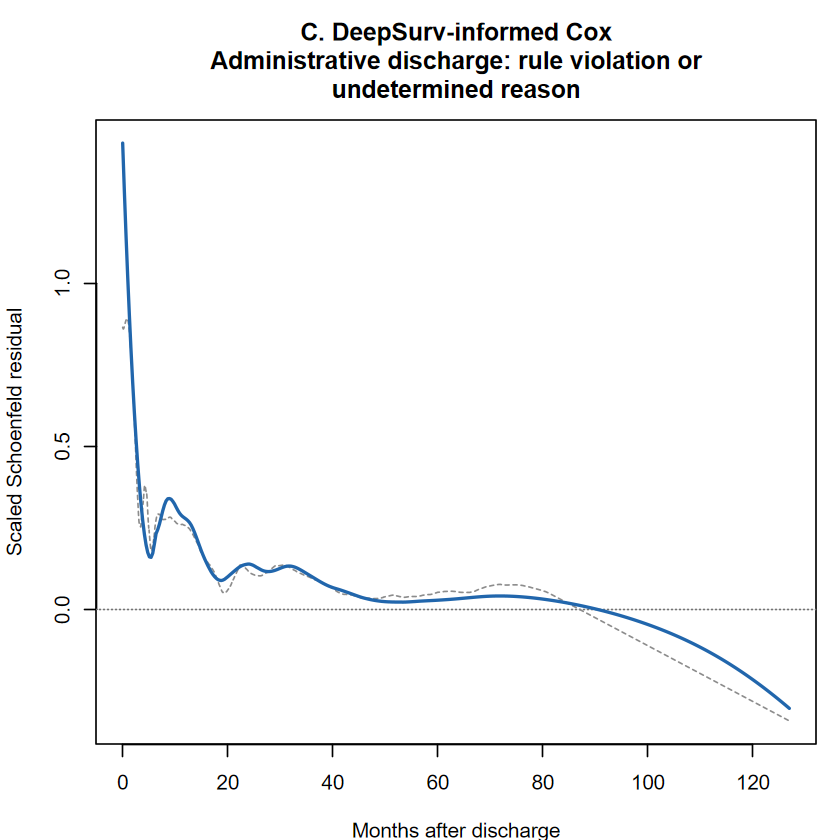

Elapsed: 0.048 minutes


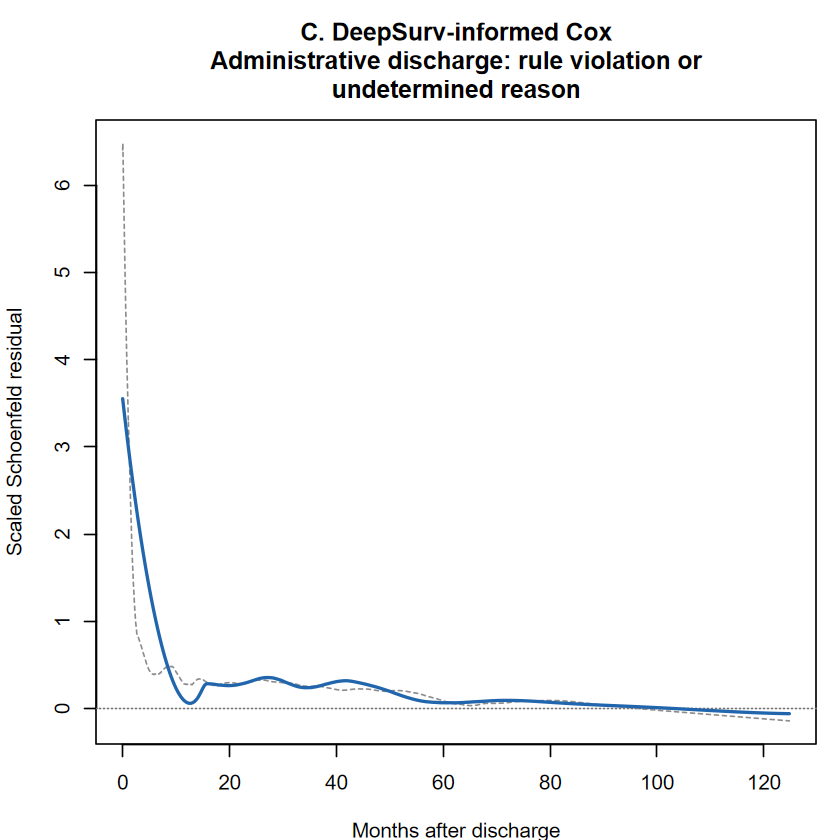

In [11]:
#| label: ds-cox-export-ph-panels
#| message: false
.t0 <- proc.time()
# Export the largest term-specific residual pattern from each base model before extra stratification.
ph_panel_sources<-list()
for(outcome in c("readmission","death")){
 result<-ds_diagnostics[[paste0(outcome,"_base")]];test<-result$ph
 z<-ds_ph[ds_ph$Outcome==outcome&ds_ph$Stage=="base"&ds_ph$Term!="GLOBAL",];term<-z$Term[which.max(z$Chi_square)]
 original<-colnames(test$y)[match(term,sub("TRUE$","",colnames(test$y)))];stopifnot(length(original)==1L,!is.na(original))
 x<-test$time;y<-test$y[,original];stopifnot(all(is.finite(x)),all(is.finite(y)))
 data<-data.frame(Time_months=x,Residual=y);smooth<-stats::loess(Residual~Time_months,data=data,span=.5,control=stats::loess.control(surface="direct"));grid<-seq(min(x),max(x),length.out=400)
 prediction<-stats::predict(smooth,newdata=data.frame(Time_months=grid));super<-stats::supsmu(x,y)
 id<-if(outcome=="readmission")"eFigure3" else "eFigure4";stem<-paste0(id,"_panelC_DeepSurv_PH_",Sys.Date(),"_",performance_signature)
 draw<-function(){graphics::par(mar=c(4,4,5,1),family="serif");graphics::plot(range(x),range(c(prediction,super$y,0),finite=TRUE),type="n",xlab="Months after discharge",ylab="Scaled Schoenfeld residual",main=paste("C. DeepSurv-informed Cox",paste(strwrap(display_term(term),width=55),collapse="\n"),sep="\n"));graphics::abline(h=0,lty=3,col="gray45");graphics::lines(super$x,super$y,lty=2,col="gray55");graphics::lines(grid,prediction,lwd=2,col="#2166ac")}
 png<-file.path(figure_dir,paste0(stem,".png"));grDevices::png(png,width=1400,height=900,res=140);draw();grDevices::dev.off()
 pdf<-file.path(figure_dir,paste0(stem,".pdf"));grDevices::pdf(pdf,width=10,height=6.4,family="Times");draw();grDevices::dev.off();draw()
 csv<-file.path(table_dir,paste0(stem,"_source.csv"));utils::write.csv(data.frame(Method="DeepSurv-informed Cox",Term=term,data),csv,row.names=FALSE)
 written<-c(written,png,pdf,csv);ph_panel_sources[[id]]<-list(png=substring(png,nchar(root)+2L),pdf=substring(pdf,nchar(root)+2L),numeric=substring(csv,nchar(root)+2L),term=term,chi_square=z$Chi_square[match(term,z$Term)],df=z$df[match(term,z$Term)],p=z$p[match(term,z$Term)])
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


In [12]:
#| label: ds-cox-interaction-shortlist
#| message: false
.t0 <- proc.time()
get_family <- function(x) {
  dplyr::case_when(
    stringr::str_detect(x, "^plan_type_corr_")       ~ "plan_type",
    stringr::str_detect(x, "^adm_motive_")           ~ "adm_motive",
    stringr::str_detect(x, "^tr_outcome_")           ~ "tr_outcome",
    stringr::str_detect(x, "^primary_sub_mod_")      ~ "primary_sub_mod",
    stringr::str_detect(x, "^first_sub_used_")       ~ "first_sub_used",
    stringr::str_detect(x, "^marital_status_")       ~ "marital_status",
    stringr::str_detect(x, "^occupation_condition_") ~ "occupation_condition",
    stringr::str_detect(x, "^cohabitation_")         ~ "cohabitation",
    stringr::str_detect(x, "^tipo_de_vivienda_")     ~ "tipo_vivienda",
    stringr::str_detect(x, "^dx_")                   ~ "dx_psiq",
    stringr::str_detect(x, "^dg_psiq_")              ~ "dg_psiq",
    stringr::str_detect(x, "^eva_")                  ~ "eva",
    stringr::str_detect(x, "^sub_dep_icd10_")        ~ "sub_dep",
    stringr::str_detect(x, "^prim_sub_freq")         ~ "prim_sub_freq",
    stringr::str_detect(x, "^ed_attainment")         ~ "education",
    stringr::str_detect(x, "^tenure_status")         ~ "tenure",
    stringr::str_detect(x, "^sex_rec_")              ~ "sex",
    stringr::str_detect(x, "^adm_age")               ~ "age",
    stringr::str_detect(x, "^dit_m$")                ~ "dit_m",
    stringr::str_detect(x, "^ethnicity$")            ~ "ethnicity",
    stringr::str_detect(x, "^polysubstance")         ~ "polysubstance",
    stringr::str_detect(x, "^any_phys_dx$")          ~ "any_phys_dx",
    TRUE                                             ~ x
  )
}
# Apply the original active filters before best-partner ranking; no new junk/admin exclusion is introduced.
shortlist<-function(z,historical=FALSE){
 required<-c("outcome","main_feature","interactor","signif_fdr_0.01","abs_corr","smd_q4_q1","smd_binarized","rank_range","abs_corr_delta");stopifnot(all(required%in%names(z)))
 excluded<-if(historical)discharge_stratum else c(discharge_stratum,removed_collinear)
 z$effect_size<-pmax(abs(z$smd_q4_q1),abs(z$smd_binarized),na.rm=TRUE)
 keep<-as.logical(z$signif_fdr_0.01)&z$abs_corr>=.10&is.finite(z$effect_size)&z$effect_size>=.15&(is.na(z$rank_range)|z$rank_range<=8)&(is.na(z$abs_corr_delta)|z$abs_corr_delta<=.05)
 if(!historical){
  stopifnot(all(z$explanation_scale=="net_risk_1_minus_survival"))
  keep<-keep&!is.na(z$horizons_seen)&z$horizons_seen==6L&is.finite(z$rank_range)&is.finite(z$abs_corr_delta)
 }
 z<-z[which(keep),];z$fam_main<-get_family(z$main_feature);z$fam_int<-get_family(z$interactor);z$score<-z$abs_corr*z$effect_size
 z<-z[z$fam_main!=z$fam_int&!startsWith(z$main_feature,"plan_type")&!startsWith(z$interactor,"plan_type")&!z$main_feature%in%excluded&!z$interactor%in%excluded,]
 z<-dplyr::group_by(z,outcome,main_feature);z<-dplyr::slice_max(z,order_by=score,n=1L,with_ties=FALSE);z<-dplyr::ungroup(z)
 z<-dplyr::group_by(z,outcome);z<-dplyr::slice_max(z,order_by=score,n=20L,with_ties=FALSE);z<-dplyr::ungroup(z);as.data.frame(dplyr::arrange(z,outcome,dplyr::desc(score)))
}
old_interactions<-utils::read.csv(source_path("deepsurv_historical_interactions"),stringsAsFactors=FALSE,check.names=FALSE)
old_horizons<-utils::read.csv(source_path("deepsurv_historical_interaction_horizons"),stringsAsFactors=FALSE,check.names=FALSE)
keys<-c("outcome","main_feature","interactor");stopifnot(!anyDuplicated(old_horizons[keys]))
old_interactions<-dplyr::left_join(old_interactions,old_horizons[c(keys,"rank_range","abs_corr_delta","direction_flip_any")],by=keys)
old_shortlist<-shortlist(old_interactions,historical=TRUE);stopifnot(sum(old_shortlist$outcome=="Readmission")==14L,sum(old_shortlist$outcome=="Death")==18L)
new_shortlist<-shortlist(interaction_source)
show_table(new_shortlist[c("outcome","main_feature","interactor","abs_corr","effect_size","score")],"New interaction shortlist under the original active ds72/pred24 rules")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


outcome,main_feature,interactor,abs_corr,effect_size,score
Death,adm_age_rec3,ethnicity,0.35348,0.80541,0.28469
Death,primary_sub_mod_cocaine_paste,adm_age_rec3,0.23721,0.53986,0.12806
Death,tipo_de_vivienda_rec2_other_unknown,adm_motive_another_sud_facility_fonodrogas_senda_previene,0.29139,0.41048,0.11961
Death,prim_sub_freq_rec,ethnicity,0.19506,0.54878,0.10704
Death,adm_motive_sanitary_sector,dx_f3_mood,0.22070,0.40715,0.08986
Death,first_sub_used_alcohol,ethnicity,0.18681,0.42471,0.07934
Death,occupation_condition_corr24_inactive,primary_sub_mod_others,0.29319,0.22237,0.06520
Death,primary_sub_mod_alcohol,dx_f3_mood,0.17002,0.37116,0.06310
Death,eva_ocupacion,tr_outcome_referral,0.15535,0.30833,0.04790
Death,eva_fisica,dx_f_any_severe_mental,0.15779,0.28497,0.04496


Elapsed: 0.002 minutes


In [13]:
#| label: ds-cox-interaction-expansion
#| message: false
.t0 <- proc.time()
# Literal dummy names retain their coding; ordinal feature families expand to their existing Cox columns.
.cols_ds<-names(py_corrected_datasets[[1L]])
.strata_excluded<-c(discharge_stratum,removed_collinear)
.is_strata_var<-function(v)startsWith(v,"plan_type")|(v%in%.strata_excluded)
.expected_family_sizes<-c(eva_consumo=2L,eva_sm=2L,ed_attainment_corr=2L,prim_sub_freq_rec=2L,eva_ocupacion=2L,eva_fisica=2L,tenure_status_household=4L,eva_fam=2L,eva_relinterp=2L,eva_transgnorma=2L,evaluacindelprocesoteraputico=1L)
.resolve_feature_terms <- function(feature, cols = .cols_ds) {
  feature <- as.character(feature)
  if (length(feature) != 1L || is.na(feature) || !nzchar(feature)) {
    stop("Invalid empty feature name in the interaction shortlist.", call. = FALSE)
  }
  if (.is_strata_var(feature)) {
    stop(sprintf("Stratification variable '%s' reached the interaction builder.", feature),
         call. = FALSE)
  }
  # A literal column always retains its original coding. Thus a selected dummy,
  # such as tr_outcome_referral, is not expanded to the whole tr_outcome family.
  if (feature %in% cols) return(feature)
  if (!(feature %in% names(.expected_family_sizes))) {
    stop(sprintf(
      "Feature '%s' is not a data column and has no approved family expansion.",
      feature
    ), call. = FALSE)
  }
  hits <- cols[startsWith(cols, paste0(feature, "_"))]
  hits <- hits[!grepl("(_score|_any|_strata)$", hits)]
  hits <- sort(setdiff(unique(hits),removed_collinear))
  expected_n <- unname(.expected_family_sizes[[feature]])
  if (length(hits) != expected_n) {
    stop(sprintf(
      "Family '%s' resolved to %d column(s), but %d were expected. Found: %s",
      feature, length(hits), expected_n,
      if (length(hits)) paste(hits, collapse = ", ") else "none"
    ), call. = FALSE)
  }
  hits
}
.assert_columns_in_all_imputations <- function(cols) {
  missing_log <- unlist(lapply(seq_along(py_corrected_datasets), function(m) {
    miss <- setdiff(cols, names(py_corrected_datasets[[m]]))
    if (length(miss)) sprintf("imputation %d: %s", m, paste(miss, collapse = ", "))
  }))
  if (length(missing_log)) {
    stop(paste("Resolved columns are absent from some imputations:",
               paste(missing_log, collapse = " | ")), call. = FALSE)
  }
  invisible(TRUE)
}
.normalise_interaction <- function(term) {
  parts <- strsplit(term, ":", fixed = TRUE)[[1]]
  paste(sort(parts), collapse = ":")
}
.build_interactions <- function(base_formula, rows, outcome_label) {
  if (is.null(rows) || !nrow(rows)) {
    return(list(
      formula = base_formula,
      audit = data.frame(),
      expansion_map = data.frame()
    ))
  }
  pair_key <- paste(rows$main_feature, rows$interactor, sep = " || ")
  if (anyDuplicated(pair_key)) {
    stop(sprintf("%s shortlist contains duplicated candidate pairs.", outcome_label),
         call. = FALSE)
  }
  all_main_terms <- character(0)
  all_interactions <- character(0)
  audit_rows <- vector("list", nrow(rows))
  map_rows <- list()
  for (i in seq_len(nrow(rows))) {
    a <- as.character(rows$main_feature[[i]])
    b <- as.character(rows$interactor[[i]])
    a_terms <- .resolve_feature_terms(a)
    b_terms <- .resolve_feature_terms(b)
    .assert_columns_in_all_imputations(c(a_terms, b_terms))
    interaction_terms <- as.vector(outer(
      a_terms, b_terms,
      FUN = function(x, y) paste(x, y, sep = ":")
    ))
    if (!length(interaction_terms)) {
      stop(sprintf("Candidate '%s x %s' produced no interaction terms.", a, b),
           call. = FALSE)
    }
    all_main_terms <- c(all_main_terms, a_terms, b_terms)
    all_interactions <- c(all_interactions, interaction_terms)
    audit_rows[[i]] <- data.frame(
      outcome = outcome_label,
      main_feature = a,
      interactor = b,
      main_columns = paste(a_terms, collapse = " + "),
      interactor_columns = paste(b_terms, collapse = " + "),
      n_interaction_terms = length(interaction_terms),
      status = "ADDED",
      stringsAsFactors = FALSE
    )
    map_rows[[length(map_rows) + 1L]] <- data.frame(
      outcome = outcome_label,
      main_feature = a,
      interactor = b,
      cox_interaction_term = interaction_terms,
      stringsAsFactors = FALSE
    )
  }
  all_main_terms <- unique(all_main_terms)
  all_interactions <- unique(all_interactions)
  add_terms <- c(all_main_terms, all_interactions)
  if (any(make.names(all_main_terms) != all_main_terms)) {
    stop("Non-syntactic column names require explicit quoting; review before fitting.",
         call. = FALSE)
  }
  updated <- stats::update(
    base_formula,
    stats::as.formula(
      paste(". ~ . +", paste(add_terms, collapse = " + ")),
      env = environment(base_formula)
    )
  )
  updated <- stats::as.formula(
    gsub("strat\\(", "strata(", paste(deparse(updated, width.cutoff = 500L), collapse = " ")),
    env = environment(base_formula)
  )
  # Failable verification: every candidate product and both components must be
  # present in the resulting formula. Interaction order is normalised because R
  # may print a:b or b:a without changing the fitted model.
  labels <- attr(stats::terms(updated), "term.labels")
  actual_interactions <- grep(":", labels, fixed = TRUE, value = TRUE)
  missing_interactions <- setdiff(
    vapply(all_interactions, .normalise_interaction, character(1)),
    vapply(actual_interactions, .normalise_interaction, character(1))
  )
  missing_main <- setdiff(all_main_terms, labels)
  if (length(missing_interactions) || length(missing_main)) {
    stop(sprintf(
      "%s formula failed the expansion audit. Missing main effects: %s. Missing interactions: %s.",
      outcome_label,
      if (length(missing_main)) paste(missing_main, collapse = ", ") else "none",
      if (length(missing_interactions)) paste(missing_interactions, collapse = ", ") else "none"
    ), call. = FALSE)
  }
  list(
    formula = updated,
    audit = do.call(rbind, audit_rows),
    expansion_map = do.call(rbind, map_rows)
  )
}
interaction_builds<-list()
for(outcome in c("readmission","death")){
 tag<-if(outcome=="readmission")"Readmission" else "Death";rows<-new_shortlist[new_shortlist$outcome==tag,]
 interaction_builds[[outcome]]<-.build_interactions(performance_formulas[[outcome]]$relaxed,rows,tag)
 stopifnot(!removed_collinear%in%all.vars(interaction_builds[[outcome]]$formula))
 show_table(interaction_builds[[outcome]]$audit,paste(tag,"interaction expansion; no silently skipped pair"))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


outcome,main_feature,interactor,main_columns,interactor_columns,n_interaction_terms,status
Readmission,primary_sub_mod_cocaine_powder,adm_motive_another_sud_facility_fonodrogas_senda_previene,primary_sub_mod_cocaine_powder,adm_motive_another_sud_facility_fonodrogas_senda_previene,1,ADDED
Readmission,ethnicity,tipo_de_vivienda_rec2_other_unknown,ethnicity,tipo_de_vivienda_rec2_other_unknown,1,ADDED
Readmission,eva_consumo,first_sub_used_cocaine_powder,eva_consumo_logro_intermedio + eva_consumo_logro_minimo,first_sub_used_cocaine_powder,2,ADDED
Readmission,tr_outcome_dropout,eva_sm,tr_outcome_dropout,eva_sm_logro_intermedio + eva_sm_logro_minimo,2,ADDED
Readmission,adm_age_rec3,ethnicity,adm_age_rec3,ethnicity,1,ADDED
Readmission,dit_m,first_sub_used_other,dit_m,first_sub_used_other,1,ADDED
Readmission,primary_sub_mod_cocaine_paste,tr_outcome_referral,primary_sub_mod_cocaine_paste,tr_outcome_referral,1,ADDED
Readmission,tr_outcome_referral,occupation_condition_corr24_inactive,tr_outcome_referral,occupation_condition_corr24_inactive,1,ADDED
Readmission,primary_sub_mod_alcohol,adm_motive_another_sud_facility_fonodrogas_senda_previene,primary_sub_mod_alcohol,adm_motive_another_sud_facility_fonodrogas_senda_previene,1,ADDED
Readmission,ed_attainment_corr,first_sub_used_cocaine_powder,ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less,first_sub_used_cocaine_powder,2,ADDED


outcome,main_feature,interactor,main_columns,interactor_columns,n_interaction_terms,status
Death,adm_age_rec3,ethnicity,adm_age_rec3,ethnicity,1,ADDED
Death,primary_sub_mod_cocaine_paste,adm_age_rec3,primary_sub_mod_cocaine_paste,adm_age_rec3,1,ADDED
Death,tipo_de_vivienda_rec2_other_unknown,adm_motive_another_sud_facility_fonodrogas_senda_previene,tipo_de_vivienda_rec2_other_unknown,adm_motive_another_sud_facility_fonodrogas_senda_previene,1,ADDED
Death,prim_sub_freq_rec,ethnicity,prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily,ethnicity,2,ADDED
Death,adm_motive_sanitary_sector,dx_f3_mood,adm_motive_sanitary_sector,dx_f3_mood,1,ADDED
Death,first_sub_used_alcohol,ethnicity,first_sub_used_alcohol,ethnicity,1,ADDED
Death,occupation_condition_corr24_inactive,primary_sub_mod_others,occupation_condition_corr24_inactive,primary_sub_mod_others,1,ADDED
Death,primary_sub_mod_alcohol,dx_f3_mood,primary_sub_mod_alcohol,dx_f3_mood,1,ADDED
Death,eva_ocupacion,tr_outcome_referral,eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo,tr_outcome_referral,2,ADDED
Death,eva_fisica,dx_f_any_severe_mental,eva_fisica_logro_intermedio + eva_fisica_logro_minimo,dx_f_any_severe_mental,2,ADDED


Elapsed: 0.001 minutes


In [14]:
#| label: ds-cox-original-interaction-guardrails
#| message: false
.t0 <- proc.time()
GVIF_THR         <- 10
MIN_CELL_EVENTS  <- 10L
SPARSE_CHECK_ALL <- TRUE
## ---- name mapping: coefficient name -> data columns, robust to level suffixes ----------
.longest_prefix_var <- function(part, varnames) {
  hits <- varnames[startsWith(part, varnames)]
  if (!length(hits)) return(NA_character_)
  hits[which.max(nchar(hits))]
}
.coef_vars <- function(cn, varnames) {
  parts <- strsplit(cn, ":", fixed = TRUE)[[1]]
  vv <- vapply(parts, .longest_prefix_var, character(1), varnames = varnames)
  if (anyNA(vv)) NA_character_ else sort(unname(vv))
}
.gvif_of <- function(v, parts, varnames) {
  if (!length(v)) return(NA_real_)
  key <- sort(parts)
  m <- vapply(names(v), function(cn) identical(.coef_vars(cn, varnames), key), logical(1))
  if (any(m)) max(v[m]) else NA_real_
}
## ---- centering: coerce logical / 2-level factor to 0-1, then subtract the mean ---------
.center_components <- function(d, vars) {
  bad <- character(0)
  for (p in vars) {
    x <- d[[p]]
    if (is.logical(x)) x <- as.numeric(x)
    if (is.factor(x) && nlevels(x) == 2L) x <- as.numeric(x) - 1
    if (is.numeric(x)) d[[p]] <- x - mean(x, na.rm = TRUE) else bad <- c(bad, p)
  }
  list(data = d, uncenterable = bad)
}
.rebuild <- function(f, keep) as.formula(
  paste(paste(deparse(f[[2]]), collapse = ""), "~", paste(keep, collapse = " + ")), env = environment(f))
.cell_support <- function(d, parts, event_col) {
  ok <- rep(TRUE, nrow(d))
  for (p in parts) ok <- ok & (as.numeric(d[[p]]) == 1)
  e <- as.numeric(d[[event_col]]); e[is.na(e)] <- 0
  c(events = sum(e[ok] == 1, na.rm = TRUE), obs = sum(ok, na.rm = TRUE))
}
.is_binary <- function(x) length(unique(x[!is.na(x)])) <= 2L
prune_interactions_collinearity <- function(f, data, event_col, thr = GVIF_THR,
                                            min_cell_events = MIN_CELL_EVENTS,
                                            sparse_check_all = SPARSE_CHECK_ALL,
                                            max_iter = 200L, label = "") {
  logs <- list()
  .add <- function(row) logs[[length(logs) + 1L]] <<- row
  vn0 <- intersect(all.vars(f), names(data))
  tl0 <- attr(terms(f), "term.labels")
  ints0 <- grep(":", tl0, fixed = TRUE, value = TRUE)
  cat(sprintf("\n===== [%s] interaction screen: %d interaction term(s) =====\n", label, length(ints0)))
  ## ---- strong hierarchy: the centering test is only valid if both main effects are in ----
  for (lab in ints0) {
    miss <- setdiff(strsplit(lab, ":", fixed = TRUE)[[1]], tl0)
    if (length(miss))
      cat(sprintf("[%s] WARNING: '%s' breaks strong hierarchy (main effect absent: %s). The centering\n           test assumes both main effects are present; its GVIF is not interpretable as an artifact test.\n",
                  label, lab, paste(miss, collapse = ", ")))
  }
  ## ---- guardrail 1: cross-cell support, an INDEPENDENT sparse-data check -----------------
  f_cur <- f
  if (isTRUE(sparse_check_all)) {
    tl <- attr(terms(f_cur), "term.labels")
    for (lab in grep(":", tl, fixed = TRUE, value = TRUE)) {
      parts <- strsplit(lab, ":", fixed = TRUE)[[1]]
      if (!all(parts %in% names(data))) next
      if (!all(vapply(parts, function(p) .is_binary(data[[p]]), logical(1)))) next
      sup <- .cell_support(data, parts, event_col)
      if (sup[["events"]] < min_cell_events) {
        f_cur <- .rebuild(f_cur, setdiff(attr(terms(f_cur), "term.labels"), lab))
        .add(data.frame(term = lab, check = "cross-cell support", gvif_raw = NA_real_, gvif_centered = NA_real_,
                        cell_events = sup[["events"]], cell_obs = sup[["obs"]],
                        action = sprintf("REMOVE (sparse 1x1 cell: %d events / %d obs < %d)",
                                         sup[["events"]], sup[["obs"]], min_cell_events), stringsAsFactors = FALSE))
      } else {
        .add(data.frame(term = lab, check = "cross-cell support", gvif_raw = NA_real_, gvif_centered = NA_real_,
                        cell_events = sup[["events"]], cell_obs = sup[["obs"]],
                        action = sprintf("KEEP (cell OK: %d events / %d obs)", sup[["events"]], sup[["obs"]]),
                        stringsAsFactors = FALSE))
      }
    }
  }
  ## ---- guardrail 2: collinearity, judged on the CENTERED parameterization ----------------
  ## Iterative, because removing one term changes the GVIF of the others.
  for (it in seq_len(max_iter)) {
    tl <- attr(terms(f_cur), "term.labels")
    ints <- grep(":", tl, fixed = TRUE, value = TRUE)
    if (!length(ints)) break
    fit <- try(survival::coxph(f_cur, data = data), silent = TRUE)
    if (inherits(fit, "try-error")) { cat(sprintf("[%s] model not evaluable; stopping.\n", label)); break }
    parts_all <- unique(unlist(strsplit(ints, ":", fixed = TRUE)))
    parts_all <- intersect(parts_all, names(data))
    cc <- .center_components(data, parts_all)
    if (length(cc$uncenterable))
      cat(sprintf("[%s] NOTE: cannot center %s (multi-level factor). Its interactions are screened on the raw GVIF only.\n",
                  label, paste(cc$uncenterable, collapse = ", ")))
    fit_c <- try(survival::coxph(f_cur, data = cc$data), silent = TRUE)
    if (inherits(fit_c, "try-error")) { cat(sprintf("[%s] centered refit failed; stopping.\n", label)); break }
    ll_gap <- abs(fit$loglik[2] - fit_c$loglik[2])
    if (ll_gap > 1e-6)
      cat(sprintf("[%s] WARNING: log-likelihood gap = %.3g between raw and centered fits. Centering should be a pure\n           reparameterization; a nonzero gap means the artifact argument does NOT hold here.\n", label, ll_gap))
    v_raw <- try(rms::vif(fit),   silent = TRUE); if (inherits(v_raw, "try-error")) break
    v_cen <- try(rms::vif(fit_c), silent = TRUE); if (inherits(v_cen, "try-error")) break
    vn <- intersect(all.vars(f_cur), names(data))
    g_raw <- vapply(ints, function(l) .gvif_of(v_raw, strsplit(l, ":", fixed = TRUE)[[1]], vn), numeric(1))
    g_cen <- vapply(ints, function(l) .gvif_of(v_cen, strsplit(l, ":", fixed = TRUE)[[1]], vn), numeric(1))
    if (anyNA(g_raw))
      cat(sprintf("[%s] WARNING: no GVIF could be matched for: %s. These terms were NOT screened.\n",
                  label, paste(ints[is.na(g_raw)], collapse = ", ")))
    offend <- ints[is.finite(g_cen) & g_cen >= thr]
    if (!length(offend)) {
      for (l in ints) .add(data.frame(term = l, check = "collinearity (centered)", gvif_raw = round(g_raw[[l]], 2),
                                      gvif_centered = round(g_cen[[l]], 2), cell_events = NA_integer_, cell_obs = NA_integer_,
                                      action = if (is.na(g_cen[[l]])) "KEEP (GVIF not evaluable)"
                                               else if (g_raw[[l]] >= thr) "KEEP (raw GVIF high but collapses on centering: product-term artifact)"
                                               else "KEEP (GVIF below threshold)", stringsAsFactors = FALSE))
      break
    }
    worst <- offend[which.max(g_cen[offend])]
    .add(data.frame(term = worst, check = "collinearity (centered)", gvif_raw = round(g_raw[[worst]], 2),
                    gvif_centered = round(g_cen[[worst]], 2), cell_events = NA_integer_, cell_obs = NA_integer_,
                    action = "REMOVE (collinearity persists after centering: substantive, not an artifact)",
                    stringsAsFactors = FALSE))
    f_cur <- .rebuild(f_cur, setdiff(tl, worst))
  }
  log_df <- if (length(logs)) do.call(rbind, logs) else
    data.frame(term = character(0), check = character(0), gvif_raw = numeric(0), gvif_centered = numeric(0),
               cell_events = integer(0), cell_obs = integer(0), action = character(0))
  list(formula = f_cur, log = log_df)
}
# Preserve the original interaction-specific support and centered-VIF screen; never remove participants.
interaction_guardrails<-list()
for(outcome in c("readmission","death")){
 input<-interaction_builds[[outcome]]$formula
 screened<-performance_cache(paste0("interaction_guard_",outcome),function()prune_interactions_collinearity(input,py_corrected_datasets[[1L]],event_col=if(outcome=="readmission")"readmit_event" else "death_event",label=outcome))
 stopifnot(!removed_collinear%in%all.vars(screened$formula),identical(formula_strata(screened$formula),formula_strata(input)))
 products<-grep(":",formula_terms(screened$formula),value=TRUE,fixed=TRUE)
 for(product in products)stopifnot(all(strsplit(product,":",fixed=TRUE)[[1L]]%in%formula_terms(screened$formula)))
 if(nrow(screened$log))stopifnot(!any(grepl("not evaluable",screened$log$action,fixed=TRUE)))
 verification<-performance_cache(paste0("interaction_guard_verify_",outcome),function(){
  d<-py_corrected_datasets[[1L]];parts<-unique(unlist(strsplit(products,":",fixed=TRUE)))
  centered<-.center_components(d,parts);stopifnot(!length(centered$uncenterable))
  fit<-survival::coxph(screened$formula,data=centered$data,na.action=stats::na.fail)
  stopifnot(fit$n==participants,all(is.finite(stats::coef(fit))))
  v<-rms::vif(fit);g<-vapply(products,function(x).gvif_of(v,strsplit(x,":",fixed=TRUE)[[1L]],names(d)),numeric(1))
  stopifnot(all(is.finite(g)),all(g<GVIF_THR));list(Verified_products=length(products),Omitted=0L)
 })
 stopifnot(verification$Verified_products==length(products),verification$Omitted==0L)
 performance_formulas[[outcome]]$interactions<-screened$formula;interaction_guardrails[[outcome]]<-screened
 show_table(screened$log,paste(outcome,"original interaction guardrails; removals concern product terms, never people"))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


term,check,gvif_raw,gvif_centered,cell_events,cell_obs,action
primary_sub_mod_cocaine_powder:adm_motive_another_sud_facility_fonodrogas_senda_previene,cross-cell support,NA,NA,283,1206,KEEP (cell OK: 283 events / 1206 obs)
ethnicity:tipo_de_vivienda_rec2_other_unknown,cross-cell support,NA,NA,174,542,KEEP (cell OK: 174 events / 542 obs)
eva_consumo_logro_intermedio:first_sub_used_cocaine_powder,cross-cell support,NA,NA,210,826,KEEP (cell OK: 210 events / 826 obs)
eva_consumo_logro_minimo:first_sub_used_cocaine_powder,cross-cell support,NA,NA,305,1240,KEEP (cell OK: 305 events / 1240 obs)
tr_outcome_dropout:eva_sm_logro_intermedio,cross-cell support,NA,NA,2718,11850,KEEP (cell OK: 2718 events / 11850 obs)
tr_outcome_dropout:eva_sm_logro_minimo,cross-cell support,NA,NA,5585,23936,KEEP (cell OK: 5585 events / 23936 obs)
primary_sub_mod_cocaine_paste:tr_outcome_referral,cross-cell support,NA,NA,913,3180,KEEP (cell OK: 913 events / 3180 obs)
tr_outcome_referral:occupation_condition_corr24_inactive,cross-cell support,NA,NA,402,1679,KEEP (cell OK: 402 events / 1679 obs)
primary_sub_mod_alcohol:adm_motive_another_sud_facility_fonodrogas_senda_previene,cross-cell support,NA,NA,278,1405,KEEP (cell OK: 278 events / 1405 obs)
ed_attainment_corr_2_completed_high_school_or_less:first_sub_used_cocaine_powder,cross-cell support,NA,NA,413,1680,KEEP (cell OK: 413 events / 1680 obs)


term,check,gvif_raw,gvif_centered,cell_events,cell_obs,action
adm_motive_another_sud_facility_fonodrogas_senda_previene:tipo_de_vivienda_rec2_other_unknown,cross-cell support,NA,NA,39,767,KEEP (cell OK: 39 events / 767 obs)
prim_sub_freq_rec_2_2_6_days_wk:ethnicity,cross-cell support,NA,NA,91,2160,KEEP (cell OK: 91 events / 2160 obs)
prim_sub_freq_rec_3_daily:ethnicity,cross-cell support,NA,NA,125,1827,KEEP (cell OK: 125 events / 1827 obs)
adm_motive_sanitary_sector:dx_f3_mood,cross-cell support,NA,NA,168,2765,KEEP (cell OK: 168 events / 2765 obs)
first_sub_used_alcohol:ethnicity,cross-cell support,NA,NA,193,3075,KEEP (cell OK: 193 events / 3075 obs)
primary_sub_mod_others:occupation_condition_corr24_inactive,cross-cell support,NA,NA,26,417,KEEP (cell OK: 26 events / 417 obs)
primary_sub_mod_alcohol:dx_f3_mood,cross-cell support,NA,NA,254,3251,KEEP (cell OK: 254 events / 3251 obs)
eva_ocupacion_logro_intermedio:tr_outcome_referral,cross-cell support,NA,NA,134,2793,KEEP (cell OK: 134 events / 2793 obs)
eva_ocupacion_logro_minimo:tr_outcome_referral,cross-cell support,NA,NA,196,3574,KEEP (cell OK: 196 events / 3574 obs)
eva_fisica_logro_intermedio:dx_f_any_severe_mental,cross-cell support,NA,NA,78,1236,KEEP (cell OK: 78 events / 1236 obs)



===== [readmission] interaction screen: 19 interaction term(s) =====

===== [death] interaction screen: 18 interaction term(s) =====


Elapsed: 0.120 minutes


In [15]:
#| label: ds-cox-oof-prediction-engine
#| message: false
.t0 <- proc.time()
# Check observed joint strata directly; candidate names do not encode the number of strata.
strata_codes <- function(data, columns) as.character(do.call(interaction, c(unname(data[columns]), list(drop = TRUE, sep = ":"))))
assert_prediction_coverage <- function(count, expected = 1L) {
  missing <- sum(count == 0L)
  unexpected <- sum(count != expected)
  if (unexpected) stop(sprintf("Prediction coverage failed: %d missing subjects; %d subjects have unexpected prediction counts. No omission or fallback is allowed.", missing, unexpected), call. = FALSE)
  invisible(TRUE)
}
performance_oof <- function(outcome, stage, repetition) performance_cache(sprintf("oof_%s_r%02d", performance_formula_key(outcome, stage), repetition), function() {
  accumulated <- matrix(0, nrow(py_corrected_datasets[[1L]]), length(performance_grid))
  legacy_rows <- list(); lp_zero <- numeric(nrow(accumulated))
  strata_columns <- formula_strata(performance_formulas[[outcome]][[stage]])
  for (i in seq_along(py_corrected_datasets)) {
    predicted_count <- integer(nrow(accumulated))
    for (k in seq_len(5L)) {
      validation_rows <- performance_folds[[repetition]][[i]][[k]]
      d <- py_corrected_datasets[[i]]
      training_strata <- strata_codes(d[-validation_rows, , drop = FALSE], strata_columns)
      validation_strata <- strata_codes(d[validation_rows, , drop = FALSE], strata_columns)
      unsupported <- sum(!validation_strata %in% training_strata)
      if (unsupported) stop(sprintf("%s %s r%d imp%d fold%d: %d validation subjects have unsupported strata; nobody was omitted.", outcome, stage, repetition, i, k, unsupported), call. = FALSE)
      fit <- survival::coxph(performance_formulas[[outcome]][[stage]], data = d[-validation_rows, , drop = FALSE], ties = "efron", x = TRUE, y = TRUE, model = TRUE, na.action = stats::na.fail)
      stopifnot(fit$n == nrow(d) - length(validation_rows), all(is.finite(stats::coef(fit))))
      baseline <- survival::basehaz(fit, centered = FALSE)
      n_strata <- if (is.null(baseline$strata)) 1L else nlevels(droplevels(factor(baseline$strata)))
      stopifnot(n_strata == length(unique(training_strata)))
      predicted <- as.matrix(pec::predictSurvProb(fit, newdata = d[validation_rows, , drop = FALSE], times = performance_grid))
      stopifnot(identical(dim(predicted), c(length(validation_rows), length(performance_grid))), all(is.finite(predicted)), min(predicted) >= 0, max(predicted) <= 1)
      if(repetition==1L){
        lp<-as.numeric(stats::predict(fit,newdata=d[validation_rows,,drop=FALSE],type="lp"))
        legacy_rows[[length(legacy_rows)+1L]]<-cbind(Imp=i,Fold=k,legacy_fold_metrics(outcome,d[-validation_rows,,drop=FALSE],d[validation_rows,,drop=FALSE],predicted,lp))
        lp_zero[validation_rows]<-lp_zero[validation_rows]+as.numeric(stats::predict(fit,newdata=d[validation_rows,,drop=FALSE],type="lp",reference="zero"))
      }
      accumulated[validation_rows, ] <- accumulated[validation_rows, ] + predicted
      predicted_count[validation_rows] <- predicted_count[validation_rows] + 1L
      record_performance_fits(1L)
    }
    assert_prediction_coverage(predicted_count)
  }
  if(repetition==1L)performance_cache(paste0("legacy_",performance_formula_key(outcome,stage)),function()list(folds=do.call(rbind,legacy_rows),lp_zero=lp_zero/5))
  accumulated / length(py_corrected_datasets)
})
performance_score <- function(outcome, stage, repetition) {
  survival_matrix <- performance_oof(outcome, stage, repetition)
  d <- py_corrected_datasets[[1L]]
  stopifnot(identical(dim(survival_matrix), c(nrow(d), length(performance_grid))), all(is.finite(survival_matrix)))
  if (outcome == "readmission") {
    time <- d$readmit_time_from_disch_m
    event <- as.integer(d$readmit_event)
    pred <- list(S = survival_matrix, grid = performance_grid, rt_val = time, re_val = event, dt_val = d$death_time_from_disch_m, de_val = as.integer(d$death_event), rt_tr = time, re_tr = event, dt_tr = d$death_time_from_disch_m, de_tr = as.integer(d$death_event))
    scored <- ibs_classical_readmit(pred, performance_horizons, method = "aalen-johansen")
  } else {
    time <- d$death_time_from_disch_m
    event <- as.integer(d$death_event)
    pred <- list(S = survival_matrix, grid = performance_grid, y_train = list(time = time, event = event), y_test = list(time = time, event = event))
    scored <- ibs_classical_point(pred, performance_horizons)
  }
  concordance <- vapply(performance_horizons, function(h) {
    marker <- 1 - survival_matrix[, match(h, performance_grid)]
    unname(survival::concordance(survival::Surv(time, event) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = h)$concordance)
  }, numeric(1L))
  stopifnot(all(is.finite(concordance)), all(is.finite(scored$ibs$ibs)))
  list(table = data.frame(Outcome = outcome, Stage = stage, Repetition = repetition, Horizon = performance_horizons, C = concordance, IBS = scored$ibs$ibs), scored_ibs = scored, coverage = data.frame(Outcome = outcome, Stage = stage, Repetition = repetition, Expected = nrow(d), Predicted = nrow(survival_matrix), Omitted = 0L))
}
# Cache each prediction/metric by formula and partition; retain the current display label when formulas coincide.
performance_task <- function(task) {
  before_fits <- performance_new_fits
  before_written <- written
  outcome <- task$Outcome
  stage <- task$Stage
  repetition <- task$Repetition
  result <- performance_cache(sprintf("metrics_%s_r%02d", performance_formula_key(outcome, stage), repetition), function() performance_score(outcome, stage, repetition))
  result$table$Stage <- stage; result$coverage$Stage <- stage
  list(table = result$table, coverage = result$coverage, new_fits = performance_new_fits - before_fits, written = setdiff(written, before_written))
}
performance_parallel <- function(tasks, worker = performance_task) {
  # Independent repetitions use separate processes; each process has one native thread.
  available <- ps::ps_system_memory()$avail / 1024^3
  memory_workers <- floor((available - shap_settings$reserve_memory_gib) / shap_settings$worker_memory_gib)
  workers <- min(performance_settings$workers, length(tasks), memory_workers)
  if (workers < 1L) stop("Insufficient free RAM for one worker plus the configured reserve.", call. = FALSE)
  old_plan <- future::plan()
  thread_names <- c("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "R_RANGER_NUM_THREADS")
  old_threads <- Sys.getenv(thread_names, unset = NA_character_)
  old_options <- options(future.globals.maxSize = shap_settings$worker_memory_gib * 1024^3)
  on.exit({
    future::plan(old_plan)
    options(old_options)
    for (j in seq_along(thread_names)) if (is.na(old_threads[j])) Sys.unsetenv(thread_names[j]) else do.call(Sys.setenv, stats::setNames(list(old_threads[j]), thread_names[j]))
  }, add = TRUE)
  do.call(Sys.setenv, stats::setNames(as.list(rep("1", length(thread_names))), thread_names))
  future::plan(future::multisession, workers = workers)
  cat("Parallel workers:", workers, "| Native threads per worker: 1 | Reserved free RAM (GiB):", shap_settings$reserve_memory_gib, "\n")
  future.apply::future_lapply(tasks, function(task) {
    options(Ncpus = 1L, ranger.num.threads = 1L)
    if (ps::ps_system_memory()$avail / 1024^3 < shap_settings$reserve_memory_gib) stop("Free RAM fell below the configured reserve; remaining work is stopped, completed caches are retained.", call. = FALSE)
    worker(task)
  }, future.seed = TRUE, future.scheduling = Inf)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [16]:
#| label: ds-cox-stratum-support-audit
#| message: false
.t0 <- proc.time()
# Distinguish sparse event information from unsupported validation strata; never merge or omit.
support<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed","interactions"))for(r in 1:10)for(i in 1:5)for(k in 1:5){
 d<-py_corrected_datasets[[i]];rows<-performance_folds[[r]][[i]][[k]];s<-strata_codes(d,formula_strata(performance_formulas[[outcome]][[stage]]));e<-if(outcome=="readmission")d$readmit_event else d$death_event
 training<-data.frame(Stratum=s[-rows],N=1L,Events=as.integer(e[-rows]));z<-stats::aggregate(cbind(N,Events)~Stratum,training,sum)
 unsupported<-sum(!s[rows]%in%z$Stratum);stopifnot(unsupported==0L)
 support[[length(support)+1L]]<-data.frame(Outcome=outcome,Stage=stage,Repetition=r,Imputation=i,Fold=k,Minimum_training_N=min(z$N),Zero_event_training_strata=sum(z$Events==0L),Unsupported_validation_people=unsupported)
}
support<-do.call(rbind,support)
show_table(stats::aggregate(cbind(Minimum_training_N,Zero_event_training_strata,Unsupported_validation_people)~Outcome+Stage,support,function(x)c(minimum=min(x),maximum=max(x),total=sum(x))),"Training-stratum audit; zero-event strata flagged without silent fallback")
show_table(data.frame(Outcome=rep(c("readmission","death"),each=3),Specification=rep(c("Base: setting strata","Relaxed PH: setting + discharge strata","Relaxed PH plus screened interactions"),2),Formula=unlist(lapply(performance_formulas,function(x)vapply(x,function(f)paste(deparse(f),collapse=" "),character(1))))),"Exact candidate formulas before predictive comparison")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Warning message in `[<-.data.frame`(`*tmp*`, , isn, value = structure(list(Minimum_training_N.minimum = c("2262", :
"provided 9 variables to replace 3 variables"


Outcome,Stage,Minimum_training_N,Zero_event_training_strata,Unsupported_validation_people
death,base,2262,2264,565800
readmission,base,2262,2264,565800
death,interactions,183,210,49200
readmission,interactions,183,210,49200
death,relaxed,183,210,49200
readmission,relaxed,183,210,49200


Outcome,Specification,Formula
readmission,Base: setting strata,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + sex_rec_woman + ethnicity + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + adm_age_rec3 + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + dg_psiq_cie_10_dg + dit_m + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + strata(plan_type_strata)"
readmission,Relaxed PH: setting + discharge strata,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + sex_rec_woman + ethnicity + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + adm_age_rec3 + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + dg_psiq_cie_10_dg + dit_m + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
readmission,Relaxed PH plus screened interactions,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + sex_rec_woman + ethnicity + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + adm_age_rec3 + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + dg_psiq_cie_10_dg + dit_m + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet) + adm_motive_another_sud_facility_fonodrogas_senda_previene + tipo_de_vivienda_rec2_other_unknown + first_sub_used_cocaine_powder + eva_sm_logro_intermedio + eva_sm_logro_minimo + first_sub_used_other + porc_pobr + adm_motive_justice_sector + primary_sub_mod_cocaine_powder:adm_motive_another_sud_facility_fonodrogas_senda_previene + ethnicity:tipo_de_vivienda_rec2_other_unknown + eva_consumo_logro_intermedio:first_sub_used_cocaine_powder + eva_consumo_logro_minimo:first_sub_used_cocaine_powder + tr_outcome_dropout:eva_sm_logro_intermedio + tr_outcome_dropout:eva_sm_logro_minimo + ethnicity:adm_age_rec3 + dit_m:first_sub_used_other + primary_sub_mod_cocaine_paste:tr_outcome_referral + tr_outcome_referral:occupation_condition_corr24_inactive + primary_sub_mod_alcohol:adm_motive_another_sud_facility_fonodrogas_senda_previene + ed_attainment_corr_2_completed_high_school_or_less:first_sub_used_cocaine_powder + ed_attainment_corr_3_completed_primary_school_or_less:first_sub_used_cocaine_powder + tr_outcome_referral:eva_relinterp_logro_intermedio + tr_outcome_referral:eva_relinterp_logro_minimo + first_sub_used_cocaine_powder:porc_pobr + primary_sub_mod_alcohol:occupation_condition_corr24_unemployed + dg_psiq_cie_10_dg:adm_motive_justice_sector + sex_rec_woman:tr_outcome_adm_discharge_adm_reasons"
death,Base: setting strata,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + primary_sub_mo

Elapsed: 0.902 minutes


In [17]:
#| label: ds-cox-c-ibs-comparisons
#| message: false
.t0 <- proc.time()
# Evaluate all three reported specifications with the same ten repeated partitions.
ds_c_ibs<-ds_coverage<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed","interactions")){
 cat("Evaluating:",outcome,stage,"| available RAM",round(ps::ps_system_memory()$avail/1024^3,2),"GiB\n");flush.console()
 values<-performance_parallel(lapply(1:10,function(r)list(Outcome=outcome,Stage=stage,Repetition=r)))
 for(value in values){record_performance_fits(value$new_fits);written<-c(written,value$written)}
 key<-paste(outcome,stage,sep="_");ds_c_ibs[[key]]<-do.call(rbind,lapply(values,`[[`,"table"));ds_coverage[[key]]<-do.call(rbind,lapply(values,`[[`,"coverage"))
 stopifnot(nrow(ds_c_ibs[[key]])==40L,all(ds_coverage[[key]]$Omitted==0L),all(ds_coverage[[key]]$Expected==participants))
 show_table(stats::aggregate(cbind(C,IBS)~Outcome+Stage+Horizon,ds_c_ibs[[key]],mean),paste(outcome,stage,"10 x 5 x 5; no omitted participant"))
}
ds_mean<-stats::aggregate(cbind(C,IBS)~Outcome+Stage+Horizon,do.call(rbind,ds_c_ibs),mean)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Evaluating: readmission base | available RAM 65.88 GiB


Outcome,Stage,Horizon,C,IBS
readmission,base,6,0.64228,0.03872
readmission,base,12,0.63149,0.06102
readmission,base,36,0.61399,0.10840
readmission,base,60,0.60859,0.13305


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Evaluating: readmission relaxed | available RAM 66.27 GiB


Outcome,Stage,Horizon,C,IBS
readmission,relaxed,6,0.64348,0.03865
readmission,relaxed,12,0.63166,0.06098
readmission,relaxed,36,0.61379,0.10839
readmission,relaxed,60,0.60844,0.13302


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
Evaluating: readmission interactions | available RAM 66.26 GiB


...

Warning message in survfit.coxph(fit, se.fit = FALSE):
"the model contains interactions; the default curve based on columm means of the X matrix is almost certainly not useful. Consider adding a newdata argument."


Warning message in survfit.coxph(fit, se.fit = FALSE):
"the model contains interactions; the default curve based on columm means of the X matrix is almost certainly not useful. Consider adding a newdata argument."


Warning message in survfit.coxph(fit, se.fit = FALSE):
"the model contains interactions; the default curve based on columm means of the X matrix is almost certainly not useful. Consider adding a newdata argument."


Outcome,Stage,Horizon,C,IBS
death,interactions,6,0.78431,0.00445
death,interactions,12,0.76686,0.00643
death,interactions,36,0.76614,0.01438
death,interactions,60,0.76434,0.02187


Elapsed: 16.747 minutes


In [18]:
#| label: ds-cox-calibration-evaluation-functions
#| message: false
.t0 <- proc.time()
# Retain each full calibration engine, binning rule and RNG; parallelize independent model/outcome jobs.
ds_calibration_task<-function(task){
 before<-performance_new_fits;before_written<-written;old_rng<-RNGkind();on.exit(do.call(RNGkind,as.list(old_rng)),add=TRUE);do.call(RNGkind,as.list(calibration_rng))
 fr<-performance_formulas$readmission[[task$Readmission]];fd<-performance_formulas$death[[task$Death]]
 key<-paste("cal",task$Outcome,substr(digest::digest(list(deparse(fr),deparse(fd)),algo="sha256"),1L,12L),task$Repeats,sep="_")
 value<-performance_cache(paste0(key,"_summary"),function(){
  if(task$Outcome=="readmission")calibrate_cscox_aj_grouped_corr(formula_readmit=fr,formula_death=fd,data=py_corrected_datasets,times=performance_horizons,n_imputations=5L,validation="cv",folds=5L,n_repeats=task$Repeats,compute_ici=TRUE,ici_times=performance_horizons,g=10L,min_bin_n=20L,ici_span=.75,tie_action="death_first",seed=seed,make_plots=FALSE,parallel_cv=FALSE,parallel_calibration=FALSE,verbose=FALSE,cache_prefix=key) else calibrate_death_km_grouped(formula=fd,data=py_corrected_datasets,times=performance_horizons,validation="cv",folds=5L,n_repeats=task$Repeats,g=10L,min_bin_n=20L,loess_span=.75,seed=seed,parallel_cv=FALSE,verbose=FALSE,cache_prefix=key)
 })
 summary<-value$pooled_summary;stopifnot(identical(as.numeric(summary$time_months),performance_horizons),all(is.finite(as.matrix(summary[,c("ici_mean","ece_mean","eo_mean")]))))
 if(task$Outcome=="readmission"){z<-value$by_repetition;stopifnot(value$settings$n_repeats==task$Repeats,nrow(z)==4L*task$Repeats,all(z$n_input==participants),all(z$n_analysis==participants),all(z$n_dropped==0L),all(z$n_excluded_calibration==0L))}else stopifnot(nrow(value$rep_results)==4L*task$Repeats,all(summary$n_reps==task$Repeats))
 coverage<-list()
 for(r in seq_len(task$Repeats)){
  count<-integer(participants);zeros<-integer(4L)
  for(k in 1:5){v<-performance_cache(paste0(key,sprintf("_r%02d_f%02d",r,k)),function()stop("Calibration fold cache is missing"));rows<-if(task$Outcome=="readmission")v$te_idx else v$test_idx;risk<-if(task$Outcome=="readmission")v$pred_fold_avg else v$risk_mat;stopifnot(nrow(risk)==length(rows),ncol(risk)==4L,all(is.finite(risk)),min(risk)>=0,max(risk)<=1);count[rows]<-count[rows]+1L;zeros<-zeros+colSums(risk==0)}
  stopifnot(all(count==1L));coverage[[r]]<-data.frame(Repetition=r,Horizon=performance_horizons,Omitted=0L,Zero_risk_entries=zeros)
 }
 list(key=task$Key,value=value,prefix=key,coverage=do.call(rbind,coverage),new_fits=performance_new_fits-before,written=setdiff(written,before_written))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [19]:
#| label: ds-cox-calibration-20x5x5
#| message: false
.t0 <- proc.time()
# Complete calibration for base, relaxed-PH and interaction pairs; do not leave c/f-like gaps.
tasks<-list()
for(stage in c("base","relaxed","interactions"))for(outcome in c("readmission","death"))tasks[[length(tasks)+1L]]<-list(Key=paste(outcome,stage,sep="_"),Outcome=outcome,Readmission=stage,Death=stage,Repeats=20L)
show_table(data.frame(Model_outcome_jobs=length(tasks),CV_repetitions=20L,Folds=5L,Imputations=5L,Maximum_workers=settings$workers,Available_RAM_GiB=ps::ps_system_memory()$avail/1024^3),"Full reported calibration budget; independent jobs only")
calculated<-performance_parallel(tasks,worker=ds_calibration_task);ds_calibration<-list()
for(value in calculated){record_performance_fits(value$new_fits);written<-c(written,value$written);ds_calibration[[value$key]]<-value;show_table(value$value$pooled_summary,paste(value$key,"20 x 5 x 5 calibration"));show_table(stats::aggregate(Zero_risk_entries~Horizon,value$coverage,sum),paste(value$key,"zero-risk counts, all participants retained"))}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Model_outcome_jobs,CV_repetitions,Folds,Imputations,Maximum_workers,Available_RAM_GiB
6,20,5,5,6,66.31284


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
[2026-10-10 21:57:03] cal_readmission_0fc94dd6c139_20_r01_f01 start (fit or cache)
[2026-10-10 21:57:17] cal_readmission_0fc94dd6c139_20_r01_f01 complete
[2026-10-10 21:57:17] cal_readmission_0fc94dd6c139_20_r01_f02 start (fit or cache)
[2026-10-10 21:57:31] cal_readmission_0fc94dd6c139_20_r01_f02 complete
[2026-10-10 21:57:31] cal_readmission_0fc94dd6c139_20_r01_f03 start (fit or cache)
[2026-10-10 21:57:46] cal_readmission_0fc94dd6c139_20_r01_f03 complete
[2026-10-10 21:57:46] cal_readmission_0fc94dd6c139_20_r01_f04 start (fit or cache)
[2026-10-10 21:58:00] cal_readmission_0fc94dd6c139_20_r01_f04 complete
[2026-10-10 21:58:00] cal_readmission_0fc94dd6c139_20_r01_f05 start (fit or cache)
[2026-10-10 21:58:15] cal_readmission_0fc94dd6c139_20_r01_f05 complete
[2026-10-10 21:58:15] cal_readmission_0fc94dd6c139_20_r02_f01 start (fit or cache)
[2026-10-10 21:58:29] cal_readmission_0fc94dd6c139_20_r02_f01 com

Warning message in coxph.fit(X, Y, istrat, offset, init, control, weights = weights, :
"Loglik converged before variable  38 ; coefficient may be infinite. "


Warning message in coxph.fit(X, Y, istrat, offset, init, control, weights = weights, :
"Loglik converged before variable  50 ; coefficient may be infinite. "


Warning message in coxph.fit(X, Y, istrat, offset, init, control, weights = weights, :
"Loglik converged before variable  34 ; coefficient may be infinite. "


...

time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.00660,0.00020,0.00631,0.00631,0.00715,0.00715,0.00103,0.00029,0.00054,0.00054,0.00167,0.00167,0.02060,0.00020,0.02025,0.02025,0.02094,0.02094,0.42308,0.01354,0.40482,0.40482,0.45286,0.45286,0.00203,0.00038,0.00148,0.00148,0.00272,0.00272,0.99064,0.00019,0.99029,0.99029,0.99098,0.99098,0.07187,1e-05,0.07185,0.07185,0.07190,0.07190,0.07255,0,0.07255,0.07255,0.07255,0.07255,20,5
12,0.00802,0.00012,0.00782,0.00782,0.00824,0.00824,0.00105,0.00022,0.00075,0.00075,0.00149,0.00149,0.02340,0.00031,0.02285,0.02285,0.02391,0.02391,0.47345,0.01362,0.45063,0.45063,0.50187,0.50187,0.00249,0.00050,0.00164,0.00164,0.00374,0.00374,0.99099,0.00014,0.99075,0.99075,0.99127,0.99127,0.11352,2e-05,0.11350,0.11350,0.11356,0.11356,0.11456,0,0.11456,0.11456,0.11456,0.11456,20,5
36,0.01021,0.00033,0.00966,0.00966,0.01101,0.01101,0.00284,0.00057,0.00142,0.00142,0.00379,0.00379,0.02381,0.00059,0.02246,0.02246,0.02475,0.02475,0.54717,0.02380,0.49890,0.49890,0.58711,0.58711,0.00426,0.00053,0.00321,0.00321,0.00514,0.00514,0.98926,0.00010,0.98906,0.98906,0.98947,0.98947,0.19969,2e-05,0.19964,0.19964,0.19973,0.19973,0.20185,0,0.20185,0.20185,0.20185,0.20185,20,5
60,0.01007,0.00022,0.00977,0.00977,0.01059,0.01059,0.00244,0.00035,0.00174,0.00174,0.00333,0.00333,0.02268,0.00061,0.02198,0.02198,0.02390,0.02390,0.56215,0.02477,0.51853,0.51853,0.60340,0.60340,0.00559,0.00073,0.00455,0.00455,0.00732,0.00732,0.98613,0.00010,0.98592,0.98592,0.98632,0.98632,0.24283,3e-05,0.24278,0.24278,0.24288,0.24288,0.24625,0,0.24625,0.24625,0.24625,0.24625,20,5


Horizon,Zero_risk_entries
6,0
12,0
36,0
60,0


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.00235,0.00006,0.00235,0.00062,0.00007,1.00604,0.00076,0.00693,0.00689,8,20
12,0.00302,0.00007,0.00300,0.00098,0.00011,1.00856,0.00061,0.01080,0.01070,8,20
36,0.00646,0.00010,0.00647,0.00198,0.00028,1.01260,0.00052,0.02893,0.02857,8,20
60,0.00892,0.00017,0.00892,0.00207,0.00024,1.02273,0.00046,0.04627,0.04524,8,20


Horizon,Zero_risk_entries
6,78
12,78
36,0
60,0


Elapsed: 63.398 minutes


In [20]:
#| label: ds-cox-specification-comparison
#| message: false
.t0 <- proc.time()
# State the agreed predictive screen explicitly; calibration and parsimony remain visible.
ds_comparison<-list()
for(outcome in c("readmission","death"))for(pair in list(c("base","relaxed"),c("relaxed","interactions"))){
 a<-ds_mean[ds_mean$Outcome==outcome&ds_mean$Stage==pair[1L],];b<-ds_mean[ds_mean$Outcome==outcome&ds_mean$Stage==pair[2L],];z<-merge(a,b,by=c("Outcome","Horizon"),suffixes=c("_base","_candidate"))
 ca<-ds_calibration[[paste(outcome,pair[1L],sep="_")]]$value$pooled_summary;cb<-ds_calibration[[paste(outcome,pair[2L],sep="_")]]$value$pooled_summary
 z$Delta_C<-z$C_candidate-z$C_base;z$Delta_IBS<-z$IBS_candidate-z$IBS_base
 z$ICI_base<-ca$ici_mean[match(z$Horizon,ca$time_months)];z$ICI_candidate<-cb$ici_mean[match(z$Horizon,cb$time_months)];z$EO_base<-ca$eo_mean[match(z$Horizon,ca$time_months)];z$EO_candidate<-cb$eo_mean[match(z$Horizon,cb$time_months)]
 z$Sufficient_predictive_gain<-z$Delta_C>=.01&z$Delta_IBS<=.001
 ds_comparison[[paste(outcome,pair[2L])]]<-z
}
show_table(do.call(rbind,ds_comparison),"Which change improves predictions? Positive delta C and negative delta IBS favour the candidate")
interaction_gain<-vapply(c("readmission","death"),function(o)any(ds_comparison[[paste(o,"interactions")]]$Sufficient_predictive_gain),logical(1))
show_table(data.frame(Outcome=names(interaction_gain),Interaction_meets_rule=interaction_gain,Action=ifelse(interaction_gain,"Material improvement: investigator review before substituting the reported relaxed-PH sensitivity","Keep the simpler relaxed-PH specification; display interaction comparator")),"Rule-based disposition; primary b/e are unchanged")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Horizon,Stage_base,C_base,IBS_base,Stage_candidate,C_candidate,IBS_candidate,Delta_C,Delta_IBS,ICI_base,ICI_candidate,EO_base,EO_candidate,Sufficient_predictive_gain
readmission,12,base,0.63149,0.06102,relaxed,0.63166,0.06098,0.00017,-0.00004,0.00786,0.00806,0.99327,0.99220,FALSE
readmission,36,base,0.61399,0.10840,relaxed,0.61379,0.10839,-0.00020,-0.00002,0.00980,0.00990,0.99171,0.99159,FALSE
readmission,6,base,0.64228,0.03872,relaxed,0.64348,0.03865,0.00120,-0.00006,0.00633,0.00662,0.99310,0.99166,FALSE
readmission,60,base,0.60859,0.13305,relaxed,0.60844,0.13302,-0.00015,-0.00003,0.00972,0.00980,0.98885,0.98978,FALSE
readmission,12,relaxed,0.63166,0.06098,interactions,0.63183,0.06099,0.00016,0.00001,0.00806,0.00802,0.99220,0.99099,FALSE
readmission,36,relaxed,0.61379,0.10839,interactions,0.61508,0.10844,0.00130,0.00005,0.00990,0.01021,0.99159,0.98926,FALSE
readmission,6,relaxed,0.64348,0.03865,interactions,0.64396,0.03866,0.00047,0.00000,0.00662,0.00660,0.99166,0.99064,FALSE
readmission,60,relaxed,0.60844,0.13302,interactions,0.60984,0.13322,0.00141,0.00020,0.00980,0.01007,0.98978,0.98613,FALSE
death,12,base,0.76029,0.00653,relaxed,0.76701,0.00643,0.00672,-0.00010,0.00245,0.00292,1.00910,1.00848,FALSE
death,36,base,0.76532,0.01442,relaxed,0.76645,0.01437,0.00113,-0.00005,0.00637,0.00640,1.01126,1.01293,FALSE


Outcome,Interaction_meets_rule,Action
readmission,FALSE,Keep the simpler relaxed-PH specification; display interaction comparator
death,FALSE,Keep the simpler relaxed-PH specification; display interaction comparator


Elapsed: 0.000 minutes


## Functional forms: one change per comparison

```{mermaid}
flowchart LR
 A[Relaxed-PH sensitivity equation] --> B[One selected predictor at a time]
 B --> C[10 x 5 x 5: risk-based Uno C and integrated IBS]
 C --> D[1 x 5 x 5: ICI and E:O; mean AICc]
 D --> E{C gain at least 0.01 and IBS increase at most 0.001?}
 E -->|No| F[Keep the current form]
 E -->|Yes| G[Flag a material candidate for final review]
```

These comparisons preserve the original age, duration and selected ordinal-family candidates. A predictor not selected by the new horizon-specific SHAP rule is not added by a graph or transformation. We do not combine individual improvements without evaluating the combination. Any material candidate is reported explicitly for the investigator's final review.

In [21]:
#| label: ds-cox-functional-candidate-register
#| message: false
.t0 <- proc.time()
# Use the original age/duration and ordinal alternatives only when their parent predictors are selected.
score_map<-list(eva_consumo=c("eva_consumo_logro_intermedio","eva_consumo_logro_minimo"),eva_sm=c("eva_sm_logro_intermedio","eva_sm_logro_minimo"),eva_ocupacion=c("eva_ocupacion_logro_intermedio","eva_ocupacion_logro_minimo"),eva_fisica=c("eva_fisica_logro_intermedio","eva_fisica_logro_minimo"),ed_attainment=c("ed_attainment_corr_2_completed_high_school_or_less","ed_attainment_corr_3_completed_primary_school_or_less"),prim_sub_freq=c("prim_sub_freq_rec_2_2_6_days_wk","prim_sub_freq_rec_3_daily"))
for(i in 1:5)for(name in names(score_map)){vars<-score_map[[name]];stopifnot(all(vars%in%names(py_corrected_datasets[[i]])));py_corrected_datasets[[i]][[paste0(name,"_score")]]<-as.numeric(py_corrected_datasets[[i]][[vars[1L]]])+2*as.numeric(py_corrected_datasets[[i]][[vars[2L]]])}
functional_candidates<-list();functional_skipped<-list()
add_functional<-function(outcome,id,parents,replacement,label){
 base<-performance_formulas[[outcome]]$relaxed
 if(!all(parents%in%formula_terms(base))){functional_skipped[[length(functional_skipped)+1L]]<<-data.frame(Outcome=outcome,Candidate=id,Reason="Parent predictor/family is not in the new relaxed-PH equation");return(invisible(NULL))}
 terms<-c(setdiff(formula_terms(base),parents),replacement)
 f<-stats::as.formula(paste(paste(deparse(base[[2L]]),collapse=""),"~",paste(terms,collapse=" + ")),env=formula_environment)
 stopifnot(identical(formula_strata(f),formula_strata(base)),!removed_collinear%in%all.vars(f))
 performance_formulas[[outcome]][[id]]<<-f;functional_candidates[[id]]<<-data.frame(Outcome=outcome,Candidate=id,Label=label)
}
for(outcome in c("readmission","death")){
 add_functional(outcome,paste0(outcome,"_age_quadratic"),"adm_age_rec3","poly(adm_age_rec3,2)","Age: quadratic")
 add_functional(outcome,paste0(outcome,"_age_spline"),"adm_age_rec3","splines::ns(adm_age_rec3,df=3)","Age: natural spline, 3 df")
 names_to_test<-if(outcome=="readmission")c("eva_consumo","eva_sm","ed_attainment")else c("eva_sm","eva_ocupacion","eva_fisica","ed_attainment","prim_sub_freq")
 for(name in names_to_test)add_functional(outcome,paste(outcome,name,"ordinal",sep="_"),score_map[[name]],paste0(name,"_score"),paste(name,"ordinal score"))
}
add_functional("readmission","readmission_duration_log","dit_m","log(dit_m+1)","Treatment duration: log(months + 1)")
add_functional("readmission","readmission_duration_spline","dit_m","splines::ns(dit_m,df=3)","Treatment duration: natural spline, 3 df")
functional_candidates<-if(length(functional_candidates))do.call(rbind,functional_candidates)else data.frame(Outcome=character(),Candidate=character(),Label=character());show_table(functional_candidates,"Registered single-change comparisons")
if(length(functional_skipped))show_table(do.call(rbind,functional_skipped),"Original candidates not applicable to the new selected formula")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Candidate,Label
readmission,readmission_age_quadratic,Age: quadratic
readmission,readmission_age_spline,"Age: natural spline, 3 df"
readmission,readmission_eva_consumo_ordinal,eva_consumo ordinal score
readmission,readmission_ed_attainment_ordinal,ed_attainment ordinal score
death,death_age_quadratic,Age: quadratic
death,death_age_spline,"Age: natural spline, 3 df"
death,death_eva_ocupacion_ordinal,eva_ocupacion ordinal score
death,death_eva_fisica_ordinal,eva_fisica ordinal score
death,death_prim_sub_freq_ordinal,prim_sub_freq ordinal score
readmission,readmission_duration_log,Treatment duration: log(months + 1)


Outcome,Candidate,Reason
readmission,readmission_eva_sm_ordinal,Parent predictor/family is not in the new relaxed-PH equation
death,death_eva_sm_ordinal,Parent predictor/family is not in the new relaxed-PH equation
death,death_ed_attainment_ordinal,Parent predictor/family is not in the new relaxed-PH equation


Elapsed: 0.001 minutes


In [22]:
#| label: ds-cox-functional-evaluation
#| message: false
.t0 <- proc.time()
# Each complete candidate is saved before moving on; no new imputation, SHAP or functional bootstrap.
functional_results<-list()
aicc<-function(outcome,stage)performance_cache(paste0("aicc_",performance_formula_key(outcome,stage)),function()vapply(py_corrected_datasets,function(d){fit<-survival::coxph(performance_formulas[[outcome]][[stage]],data=d,ties="efron",na.action=stats::na.fail);stopifnot(fit$n==participants,all(is.finite(stats::coef(fit))));k<-length(stats::coef(fit));stopifnot(fit$nevent>k+1L);record_performance_fits(1L);stats::AIC(fit)+2*k*(k+1)/(fit$nevent-k-1)},numeric(1)))
base_cal<-performance_parallel(lapply(c("readmission","death"),function(o)list(Key=o,Outcome=o,Readmission="relaxed",Death="relaxed",Repeats=1L)),worker=ds_calibration_task)
names(base_cal)<-vapply(base_cal,`[[`,character(1),"key")
for(value in base_cal){record_performance_fits(value$new_fits);written<-c(written,value$written)}
for(j in seq_len(nrow(functional_candidates))){
 item<-functional_candidates[j,];outcome<-item$Outcome;id<-item$Candidate
 result<-performance_cache(paste0("functional_complete_",id),function(){
  values<-performance_parallel(lapply(1:10,function(r)list(Outcome=outcome,Stage=id,Repetition=r)))
  for(value in values){record_performance_fits(value$new_fits);written<<-c(written,value$written)}
  repetitions<-do.call(rbind,lapply(values,`[[`,"table"));stopifnot(nrow(repetitions)==40L,all(vapply(values,function(x)all(x$coverage$Omitted==0L),logical(1))))
  before<-ds_c_ibs[[paste0(outcome,"_relaxed")]];z<-merge(before,repetitions,by=c("Outcome","Repetition","Horizon"),suffixes=c("_base","_candidate"))
  z$Delta_C<-z$C_candidate-z$C_base;z$Delta_IBS<-z$IBS_candidate-z$IBS_base
  comparison<-stats::aggregate(cbind(C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS)~Horizon,z,mean)
  task<-list(Key=id,Outcome=outcome,Readmission=if(outcome=="readmission")id else "relaxed",Death=if(outcome=="death")id else "relaxed",Repeats=1L)
  cv<-ds_calibration_task(task);written<<-c(written,cv$written);base<-base_cal[[outcome]]$value$pooled_summary;after<-cv$value$pooled_summary
  comparison$ICI_base<-base$ici_mean;comparison$ICI_candidate<-after$ici_mean;comparison$EO_base<-base$eo_mean;comparison$EO_candidate<-after$eo_mean
  comparison$Delta_AICc<-mean(aicc(outcome,id))-mean(aicc(outcome,"relaxed"))
  comparison$Sufficient_predictive_gain<-comparison$Delta_C>=.01&comparison$Delta_IBS<=.001
  comparison$Action<-if(any(comparison$Sufficient_predictive_gain))"Material candidate: final investigator review required before substitution"else "Retain current form"
  list(comparison=cbind(item,comparison),repetitions=repetitions,calibration=cv$value$pooled_summary,coverage=cv$coverage)
 })
 functional_results[[id]]<-result;show_table(result$comparison,paste(item$Label,"versus the unchanged relaxed-PH equation"))
}
functional_summary<-if(length(functional_results))do.call(rbind,lapply(functional_results,`[[`,"comparison"))else data.frame(Candidate=character(),Sufficient_predictive_gain=logical());show_table(functional_summary,"Complete functional-form exploration: all applicable original candidates")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Parallel workers: 2 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
[2026-10-10 23:00:22] cal_readmission_4a7dbd1b15a3_1_r01_f01 start (fit or cache)
[2026-10-10 23:00:33] cal_readmission_4a7dbd1b15a3_1_r01_f01 complete
[2026-10-10 23:00:33] cal_readmission_4a7dbd1b15a3_1_r01_f02 start (fit or cache)
[2026-10-10 23:00:45] cal_readmission_4a7dbd1b15a3_1_r01_f02 complete
[2026-10-10 23:00:45] cal_readmission_4a7dbd1b15a3_1_r01_f03 start (fit or cache)
[2026-10-10 23:00:57] cal_readmission_4a7dbd1b15a3_1_r01_f03 complete
[2026-10-10 23:00:57] cal_readmission_4a7dbd1b15a3_1_r01_f04 start (fit or cache)
[2026-10-10 23:01:08] cal_readmission_4a7dbd1b15a3_1_r01_f04 complete
[2026-10-10 23:01:08] cal_readmission_4a7dbd1b15a3_1_r01_f05 start (fit or cache)
[2026-10-10 23:01:20] cal_readmission_4a7dbd1b15a3_1_r01_f05 complete
[2026-10-10 23:00:04] cal_death_4a7dbd1b15a3_1_r01_f01 start (fit or cache)
[2026-10-10 23:00:08] cal_death_4a7dbd1b15a3_1_r01_f01 complete
[2026-10-10 23:00:

Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 
[2026-10-10 23:05:14] cal_readmission_06bc9f905594_1_r01_f01 start (fit or cache)


[2026-10-10 23:05:26] cal_readmission_06bc9f905594_1_r01_f01 complete


[2026-10-10 23:05:26] cal_readmission_06bc9f905594_1_r01_f02 start (fit or cache)


[2026-10-10 23:05:38] cal_readmission_06bc9f905594_1_r01_f02 complete


...

[2026-10-10 23:49:40] cal_readmission_ba6e45bdb508_1_r01_f05 complete


Warning message in data.frame(..., check.names = FALSE):
"los nombres de fila se encontraron a partir de una variable corta y se descartaron"


Outcome,Candidate,Label,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,EO_base,EO_candidate,Delta_AICc,Sufficient_predictive_gain,Action
readmission,readmission_duration_spline,"Treatment duration: natural spline, 3 df",6,0.64348,0.64333,-0.00015,0.03865,0.03865,0e+00,0.00664,0.00660,0.99171,0.99136,-24.21493,FALSE,Retain current form
readmission,readmission_duration_spline,"Treatment duration: natural spline, 3 df",12,0.63166,0.63169,0.00002,0.06098,0.06097,0e+00,0.00800,0.00801,0.99224,0.99190,-24.21493,FALSE,Retain current form
readmission,readmission_duration_spline,"Treatment duration: natural spline, 3 df",36,0.61379,0.61419,0.00040,0.10839,0.10836,-3e-05,0.01004,0.01058,0.99165,0.99141,-24.21493,FALSE,Retain current form
readmission,readmission_duration_spline,"Treatment duration: natural spline, 3 df",60,0.60844,0.60918,0.00074,0.13302,0.13298,-4e-05,0.00997,0.01088,0.98986,0.98955,-24.21493,FALSE,Retain current form


Outcome,Candidate,Label,Horizon,C_base,C_candidate,Delta_C,IBS_base,IBS_candidate,Delta_IBS,ICI_base,ICI_candidate,EO_base,EO_candidate,Delta_AICc,Sufficient_predictive_gain,Action
readmission,readmission_age_quadratic,Age: quadratic,6,0.64348,0.64311,-0.00037,0.03865,0.03865,0e+00,0.00664,0.00681,0.99171,0.99144,-69.42950,FALSE,Retain current form
readmission,readmission_age_quadratic,Age: quadratic,12,0.63166,0.63180,0.00014,0.06098,0.06097,-1e-05,0.00800,0.00803,0.99224,0.99190,-69.42950,FALSE,Retain current form
readmission,readmission_age_quadratic,Age: quadratic,36,0.61379,0.61453,0.00074,0.10839,0.10835,-4e-05,0.01004,0.01025,0.99165,0.99106,-69.42950,FALSE,Retain current form
readmission,readmission_age_quadratic,Age: quadratic,60,0.60844,0.60964,0.00120,0.13302,0.13297,-5e-05,0.00997,0.01053,0.98986,0.98898,-69.42950,FALSE,Retain current form
readmission,readmission_age_spline,"Age: natural spline, 3 df",6,0.64348,0.64311,-0.00037,0.03865,0.03865,0e+00,0.00664,0.00669,0.99171,0.99146,-61.82880,FALSE,Retain current form
readmission,readmission_age_spline,"Age: natural spline, 3 df",12,0.63166,0.63185,0.00019,0.06098,0.06097,-1e-05,0.00800,0.00815,0.99224,0.99192,-61.82880,FALSE,Retain current form
readmission,readmission_age_spline,"Age: natural spline, 3 df",36,0.61379,0.61452,0.00074,0.10839,0.10835,-3e-05,0.01004,0.01005,0.99165,0.99109,-61.82880,FALSE,Retain current form
readmission,readmission_age_spline,"Age: natural spline, 3 df",60,0.60844,0.60958,0.00115,0.13302,0.13298,-5e-05,0.00997,0.01029,0.98986,0.98902,-61.82880,FALSE,Retain current form
readmission,readmission_eva_consumo_ordinal,eva_consumo ordinal score,6,0.64348,0.64308,-0.00040,0.03865,0.03865,0e+00,0.00664,0.00646,0.99171,0.99169,6.69816,FALSE,Retain current form
readmission,readmission_eva_consumo_ordinal,eva_consumo ordinal score,12,0.63166,0.63136,-0.00031,0.06098,0.06098,0e+00,0.00800,0.00786,0.99224,0.99220,6.69816,FALSE,Retain current form


Elapsed: 50.936 minutes


In [23]:
#| label: ds-cox-paired-bootstrap-functions
#| message: false
.t0 <- proc.time()
bootstrap_job <- function(job, B, seed) {
  Sys.setenv(OMP_NUM_THREADS = 1, OPENBLAS_NUM_THREADS = 1, MKL_NUM_THREADS = 1, R_RANGER_NUM_THREADS = 1)
  options(Ncpus = 1L)
  set.seed(as.integer(seed), kind = "Mersenne-Twister", normal.kind = "Inversion", sample.kind = "Rejection")
  n <- nrow(job$values)
  out <- matrix(NA_real_, nrow = ncol(job$values), ncol = B, dimnames = list(colnames(job$values), paste0("b", seq_len(B))))
  counter <- get("concordancefit", envir = asNamespace("survival"))
  for (b in seq_len(B)) {
    index <- sample.int(n, n, replace = TRUE)
    if (job$Metric == "IBS") {
      counts <- tabulate(index, nbins = n)
      out[, b] <- as.numeric(counts %*% job$values) / n
    } else {
      y <- survival::Surv(job$time[index], job$event[index])
      out[, b] <- vapply(seq_len(ncol(job$values)), function(a) {
        fit <- counter(y, job$values[index, a], timewt = "n/G2", reverse = TRUE, ymax = job$Horizon, std.err = FALSE)
        z <- fit$count
        unname((z[["concordant"]] + z[["tied.x"]] / 2) / (z[["concordant"]] + z[["discordant"]] + z[["tied.x"]]))
      }, numeric(1L))
    }
  }
  stopifnot(all(is.finite(out)))
  out
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [24]:
#| label: ds-cox-paired-inputs-and-controls
#| message: false
.t0 <- proc.time()
# Pair new sensitivity predictions with the executed primary-model OOF predictions on identical patients.
consolidated<-readRDS(resolve_path(config$publication_sources$Table2_5));manifest<-consolidated$paired_cache_manifest
stopifnot(identical(digest::digest(historical_folds,algo="sha256"),consolidated$fold_signature))
paired_inputs<-list();registry<-list();paired_points<-list();paired_controls<-list();legacy_current<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed","interactions")){
 id<-paste0("ds_",outcome,"_",stage);key<-performance_formula_key(outcome,stage)
 s<-performance_cache(paste0("oof_",key,"_r01"),function()stop("Missing first-partition OOF cache"));m<-performance_cache(paste0("metrics_",key,"_r01"),function()stop("Missing first-partition score cache"))
 paired_inputs[[id]]<-list(risk=1-s[,match(performance_horizons,performance_grid),drop=FALSE],ibs=sweep(m$scored_ibs$contrib_trapezoid,2L,performance_horizons,"/"))
 paired_points[[id]]<-data.frame(Model=id,Outcome=outcome,Horizon=performance_horizons,C=m$table$C,IBS=m$table$IBS)
 registry[[id]]<-data.frame(Model=id,Outcome=outcome,Stage=stage)
 legacy_current[[id]]<-performance_cache(paste0("legacy_",key),function()stop("Missing original-convention summaries"))
 rm(s,m);invisible(gc())
}
for(id in c("Full_readmission","b","Full_mortality","e")){
 row<-manifest[manifest$Model==id,];stopifnot(nrow(row)==1L)
 pp<-resolve_path(row$Prediction_path);mp<-resolve_path(row$Metric_path)
 stopifnot(identical(digest::digest(file=pp,algo="sha256"),row$Prediction_sha256),identical(digest::digest(file=mp,algo="sha256"),row$Metric_sha256))
 s<-readRDS(pp)$value;m<-readRDS(mp)$value;outcome<-if(id%in%c("Full_readmission","b"))"readmission"else "death"
 paired_inputs[[id]]<-list(risk=1-s[,match(performance_horizons,performance_grid),drop=FALSE],ibs=sweep(m$scored_ibs$contrib_trapezoid,2L,performance_horizons,"/"))
 paired_points[[id]]<-data.frame(Model=id,Outcome=outcome,Horizon=performance_horizons,C=m$table$C,IBS=m$table$IBS);registry[[id]]<-data.frame(Model=id,Outcome=outcome,Stage="primary_reference")
 rm(s,m);invisible(gc())
}
registry<-do.call(rbind,registry);paired_points<-do.call(rbind,paired_points)
for(id in registry$Model){
 outcome<-registry$Outcome[registry$Model==id];d<-py_corrected_datasets[[1L]];tt<-if(outcome=="readmission")d$readmit_time_from_disch_m else d$death_time_from_disch_m;ee<-if(outcome=="readmission")d$readmit_event else d$death_event
 x<-paired_inputs[[id]];stopifnot(identical(dim(x$risk),c(participants,4L)),identical(dim(x$ibs),c(participants,4L)),all(is.finite(x$risk)),all(is.finite(x$ibs)))
 cc<-vapply(1:4,function(h){marker<-x$risk[,h];unname(survival::concordance(survival::Surv(tt,ee)~marker,timewt="n/G2",reverse=TRUE,ymax=performance_horizons[h])$concordance)},numeric(1))
 ref<-paired_points[paired_points$Model==id,];gap<-max(abs(cc-ref$C),abs(colMeans(x$ibs)-ref$IBS));stopifnot(gap<1e-10)
 paired_controls[[id]]<-data.frame(Model=id,Maximum_error=gap,Omitted=0L)
}
show_table(do.call(rbind,paired_controls),"Current first-partition point controls before paired resampling")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Model,Maximum_error,Omitted
ds_readmission_base,0,0
ds_readmission_relaxed,0,0
ds_readmission_interactions,0,0
ds_death_base,0,0
ds_death_relaxed,0,0
ds_death_interactions,0,0
Full_readmission,0,0
b,0,0
Full_mortality,0,0
e,0,0


Elapsed: 0.551 minutes


In [25]:
#| label: ds-cox-paired-bootstrap-500
#| message: false
.t0 <- proc.time()
# Preserve 08 seeds, participant pairing and fixed IBS contributions; do not refit models in bootstrap.
jobs<-list();job_seeds<-integer()
for(outcome in c("readmission","death"))for(h in 1:4){
 ids<-registry$Model[registry$Outcome==outcome];d<-py_corrected_datasets[[1L]]
 jobs[[length(jobs)+1L]]<-list(Key=paste("C",outcome,performance_horizons[h],sep="_"),Metric="C",Outcome=outcome,Horizon=performance_horizons[h],values=vapply(ids,function(id)paired_inputs[[id]]$risk[,h],numeric(participants)),time=if(outcome=="readmission")d$readmit_time_from_disch_m else d$death_time_from_disch_m,event=if(outcome=="readmission")d$readmit_event else d$death_event)
}
ibs_columns<-do.call(cbind,lapply(names(paired_inputs),function(id){z<-paired_inputs[[id]]$ibs;colnames(z)<-paste(id,performance_horizons,sep="::");z}))
jobs[[9L]]<-list(Key="IBS_all_arms",Metric="IBS",values=ibs_columns);job_seeds<-c(seed+1:8,seed)
# Three draws check execution and timing only; they never supply a confidence interval.
pilot<-list()
for(j in seq_along(jobs)){start<-proc.time()[["elapsed"]];x<-bootstrap_job(jobs[[j]],3L,job_seeds[j]);pilot[[j]]<-data.frame(Job=jobs[[j]]$Key,Seconds=proc.time()[["elapsed"]]-start,Planned_B=500L);stopifnot(all(is.finite(x)))
 set.seed(as.integer(job_seeds[j]),kind="Mersenne-Twister",normal.kind="Inversion",sample.kind="Rejection");job<-jobs[[j]];index<-sample.int(participants,participants,replace=TRUE)
 control<-if(job$Metric=="IBS")colMeans(job$values[index,,drop=FALSE])else vapply(seq_len(ncol(job$values)),function(a){tt<-job$time[index];ee<-job$event[index];marker<-job$values[index,a];unname(survival::concordance(survival::Surv(tt,ee)~marker,timewt="n/G2",reverse=TRUE,ymax=job$Horizon)$concordance)},numeric(1))
 stopifnot(max(abs(x[,1L]-control))<1e-10);rm(x)}
pilot<-do.call(rbind,pilot);pilot$Projected_seconds_B500<-pilot$Seconds/3*500;show_table(pilot,"Non-reportable resource pilot; full paired intervals use all 500 draws")
bootstrap_task<-function(j){before<-written;value<-performance_cache(paste0("bootstrap_",jobs[[j]]$Key),function()bootstrap_job(jobs[[j]],500L,job_seeds[j]));stopifnot(ncol(value)==500L,all(is.finite(value)));list(job=j,value=value,written=setdiff(written,before))}
values<-performance_parallel(as.list(seq_along(jobs)),worker=bootstrap_task);bootstrap_values<-list()
for(value in values){bootstrap_values[[jobs[[value$job]]$Key]]<-value$value;written<-c(written,value$written)}
by_model<-pairwise<-list()
for(outcome in c("readmission","death"))for(h in 1:4)for(metric in c("C","IBS")){
 ids<-registry$Model[registry$Outcome==outcome];point<-paired_points[paired_points$Outcome==outcome&paired_points$Horizon==performance_horizons[h],];point<-point[match(ids,point$Model),]
 values<-if(metric=="C")bootstrap_values[[paste("C",outcome,performance_horizons[h],sep="_")]][ids,,drop=FALSE]else bootstrap_values$IBS_all_arms[paste(ids,performance_horizons[h],sep="::"),,drop=FALSE]
 ci<-t(apply(values,1L,stats::quantile,probs=c(.025,.975),names=FALSE,type=7L));by_model[[length(by_model)+1L]]<-data.frame(Outcome=outcome,Model=ids,Horizon=performance_horizons[h],Metric=metric,Estimate=point[[metric]],Lower95=ci[,1L],Upper95=ci[,2L],Valid_B=500L)
 pairs<-utils::combn(seq_along(ids),2L)
 for(k in seq_len(ncol(pairs))){a<-pairs[1L,k];b<-pairs[2L,k];delta<-values[a,]-values[b,];ci<-stats::quantile(delta,c(.025,.975),names=FALSE,type=7L);pairwise[[length(pairwise)+1L]]<-data.frame(Outcome=outcome,A=ids[a],B=ids[b],Horizon=performance_horizons[h],Metric=metric,Delta_A_minus_B=point[[metric]][a]-point[[metric]][b],Lower95=ci[1L],Upper95=ci[2L],Valid_B=500L)}
}
by_model<-do.call(rbind,by_model);pairwise<-do.call(rbind,pairwise);stopifnot(all(by_model$Valid_B==500L),all(pairwise$Valid_B==500L))
show_table(by_model,"Formal original-partition estimates and 95% percentile intervals")
show_table(pairwise,"All paired sensitivity/reference contrasts; delta A minus B")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Job,Seconds,Planned_B,Projected_seconds_B500
C_readmission_6,0.58,500,96.66667
C_readmission_12,0.57,500,95.00000
C_readmission_36,0.76,500,126.66667
C_readmission_60,0.86,500,143.33333
C_death_6,0.53,500,88.33333
C_death_12,0.67,500,111.66667
C_death_36,0.58,500,96.66667
C_death_60,0.54,500,90.00000
IBS_all_arms,0.02,500,3.33333


Parallel workers: 6 | Native threads per worker: 1 | Reserved free RAM (GiB): 20 


Outcome,Model,Horizon,Metric,Estimate,Lower95,Upper95,Valid_B
readmission,ds_readmission_base,6,C,0.64235,0.63458,0.65049,500
readmission,ds_readmission_relaxed,6,C,0.64355,0.63563,0.65142,500
readmission,ds_readmission_interactions,6,C,0.64395,0.63618,0.65178,500
readmission,Full_readmission,6,C,0.64374,0.63589,0.65179,500
readmission,b,6,C,0.64583,0.63795,0.65345,500
readmission,ds_readmission_base,6,IBS,0.03871,0.03768,0.03986,500
readmission,ds_readmission_relaxed,6,IBS,0.03865,0.03762,0.03980,500
readmission,ds_readmission_interactions,6,IBS,0.03866,0.03762,0.03982,500
readmission,Full_readmission,6,IBS,0.03866,0.03762,0.03981,500
readmission,b,6,IBS,0.03865,0.03762,0.03980,500


Outcome,A,B,Horizon,Metric,Delta_A_minus_B,Lower95,Upper95,Valid_B
readmission,ds_readmission_base,ds_readmission_relaxed,6,C,-0.00120,-0.00250,0.00003,500
readmission,ds_readmission_base,ds_readmission_interactions,6,C,-0.00160,-0.00357,0.00042,500
readmission,ds_readmission_base,Full_readmission,6,C,-0.00139,-0.00375,0.00080,500
readmission,ds_readmission_base,b,6,C,-0.00348,-0.00563,-0.00127,500
readmission,ds_readmission_relaxed,ds_readmission_interactions,6,C,-0.00040,-0.00204,0.00117,500
readmission,ds_readmission_relaxed,Full_readmission,6,C,-0.00019,-0.00213,0.00157,500
readmission,ds_readmission_relaxed,b,6,C,-0.00228,-0.00410,-0.00055,500
readmission,ds_readmission_interactions,Full_readmission,6,C,0.00021,-0.00160,0.00193,500
readmission,ds_readmission_interactions,b,6,C,-0.00188,-0.00372,0.00006,500
readmission,Full_readmission,b,6,C,-0.00210,-0.00354,-0.00065,500


Elapsed: 4.322 minutes


## Manuscript sources and reporting conventions

**Table 2** uses the same original partition, pooling, dense-grid integrated IBS and paired 500-draw bootstrap as 08. Its readmission IBS retains the approved net-prediction/competing-risk-weighting convention; it is not relabelled as CIF IBS. Censoring weights are re-estimated for C in each draw; the original IBS contributions remain fixed. These intervals condition on fitted OOF models and the completed development preprocessing.

**eTable 9** preserves its original sensitivity-table convention: mean over 25 fold/imputation metrics, original LP centering, and the original IBS integration from 3 to 60 months over five time points. Its calibration uses the complete 20 x 5 x 5 run. The eTable 9 IBS is therefore not the Table 2 IBS. Both are explicitly identified; neither is presented as the simple average of Brier scores. Risk-based C/IBS under the common 07/08 definitions govern predictive screening. The LP column is descriptive and cannot substitute for stratum-specific absolute risk.

In [26]:
#| label: ds-cox-etable9-and-table2-sources
#| message: false
.t0 <- proc.time()
# Export complete final table sources, preserving the different original reporting conventions.
etable9<-table2_ds<-list()
for(outcome in c("readmission","death"))for(stage in c("base","relaxed","interactions")){
 id<-paste0("ds_",outcome,"_",stage);legacy<-legacy_current[[id]]$folds;stopifnot(nrow(legacy)==25L,!anyDuplicated(legacy[c("Imp","Fold")]))
 means<-colMeans(legacy[,c("C_lp","IBS_original_3_60","C6","C12","C36","C60")]);cal<-ds_calibration[[paste(outcome,stage,sep="_")]]$value$pooled_summary;at60<-cal[cal$time_months==60,];stopifnot(nrow(at60)==1L)
 etable9[[id]]<-data.frame(Outcome=outcome,Specification=stage,Model=id,C_LP=means[["C_lp"]],IBS=means[["IBS_original_3_60"]],ICI=at60$ici_mean,EO=at60$eo_mean,C6=means[["C6"]],C12=means[["C12"]],C36=means[["C36"]],C60=means[["C60"]],C_aggregation="Mean of 25 validation-fold metrics",IBS_definition="Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",LP_reference="Original predict.coxph default centering within strata")
}
etable9<-do.call(rbind,etable9);stopifnot(nrow(etable9)==6L,all(is.finite(as.matrix(etable9[c("C_LP","IBS","ICI","EO","C6","C12","C36","C60")]))))
get_delta<-function(A,B,h,metric){z<-pairwise[pairwise$A==A&pairwise$B==B&pairwise$Horizon==h&pairwise$Metric==metric,];if(nrow(z)==1L)return(c(z$Delta_A_minus_B,z$Lower95,z$Upper95));z<-pairwise[pairwise$A==B&pairwise$B==A&pairwise$Horizon==h&pairwise$Metric==metric,];stopifnot(nrow(z)==1L);c(-z$Delta_A_minus_B,-z$Upper95,-z$Lower95)}
for(outcome in c("readmission","death"))for(h in performance_horizons){
 id<-paste0("ds_",outcome,"_relaxed");reference<-if(outcome=="readmission")"b"else "Full_mortality"
 c<-by_model[by_model$Model==id&by_model$Horizon==h&by_model$Metric=="C",];b<-by_model[by_model$Model==id&by_model$Horizon==h&by_model$Metric=="IBS",];cal<-ds_calibration[[paste0(outcome,"_relaxed")]]$value$pooled_summary;cal<-cal[cal$time_months==h,]
 dc<-get_delta(reference,id,h,"C");di<-get_delta(reference,id,h,"IBS")
 stopifnot(nrow(c)==1L,nrow(b)==1L,nrow(cal)==1L)
 table2_ds[[length(table2_ds)+1L]]<-data.frame(Model=id,Outcome=outcome,Horizon=h,C=c$Estimate,C_lower=c$Lower95,C_upper=c$Upper95,IBS=b$Estimate,IBS_lower=b$Lower95,IBS_upper=b$Upper95,ICI=cal$ici_mean,EO=cal$eo_mean,Reference_A=reference,Delta_C=dc[1L],Delta_C_lower=dc[2L],Delta_C_upper=dc[3L],Delta_IBS=di[1L],Delta_IBS_lower=di[2L],Delta_IBS_upper=di[3L],Valid_B=500L)
}
table2_ds<-do.call(rbind,table2_ds);stopifnot(nrow(table2_ds)==8L,!anyNA(table2_ds))
export_source<-function(id,value){path<-file.path(table_dir,paste0(id,"_",Sys.Date(),"_",performance_signature,".csv"));utils::write.csv(value,path,row.names=FALSE,na="");written<<-c(written,path);substring(path,nchar(root)+2L)}
exports<-list(Table2=export_source("Table2_DeepSurv_source",table2_ds),eTable9=export_source("eTable9_DeepSurv_source",etable9),PH=export_source("eFigures3_4_DeepSurv_PH_source",ds_ph),Comparisons=export_source("Table2_DeepSurv_paired_comparisons",pairwise))
show_table(etable9,"eTable 9: complete base, relaxed-PH and interaction sensitivity results")
show_table(table2_ds,"Table 2: DeepSurv-informed relaxed-PH rows; delta primary reference minus sensitivity")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Specification,Model,C_LP,IBS,ICI,EO,C6,C12,C36,C60,C_aggregation,IBS_definition,LP_reference
readmission,base,ds_readmission_base,0.57710,0.13736,0.00972,0.98885,0.64240,0.63155,0.61397,0.60861,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata
readmission,relaxed,ds_readmission_relaxed,0.57435,0.13732,0.00980,0.98978,0.64360,0.63171,0.61377,0.60848,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata
readmission,interactions,ds_readmission_interactions,0.57608,0.13756,0.01007,0.98613,0.64383,0.63159,0.61474,0.60953,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata
death,base,ds_death_base,0.74141,0.02287,0.00881,1.01977,0.76557,0.75940,0.76474,0.76341,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata
death,relaxed,ds_death_relaxed,0.74194,0.02284,0.00884,1.02374,0.78341,0.76646,0.76593,0.76347,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata
death,interactions,ds_death_interactions,0.74446,0.02286,0.00892,1.02273,0.78367,0.76609,0.76547,0.76377,Mean of 25 validation-fold metrics,"Original IPCW integral over 3,6,12,36,60 months; mean of 25 fold metrics",Original predict.coxph default centering within strata


Model,Outcome,Horizon,C,C_lower,C_upper,IBS,IBS_lower,IBS_upper,ICI,EO,Reference_A,Delta_C,Delta_C_lower,Delta_C_upper,Delta_IBS,Delta_IBS_lower,Delta_IBS_upper,Valid_B
ds_readmission_relaxed,readmission,6,0.64355,0.63563,0.65142,0.03865,0.03762,0.03980,0.00662,0.99166,b,0.00228,0.00055,0.00410,-0.00001,-0.00002,0.00001,500
ds_readmission_relaxed,readmission,12,0.63176,0.62575,0.63863,0.06098,0.05979,0.06237,0.00806,0.99220,b,0.00110,-0.00034,0.00257,-0.00001,-0.00003,0.00002,500
ds_readmission_relaxed,readmission,36,0.61386,0.60899,0.61880,0.10838,0.10693,0.10986,0.00990,0.99159,b,0.00064,-0.00047,0.00184,0.00006,0.00000,0.00012,500
ds_readmission_relaxed,readmission,60,0.60858,0.60395,0.61336,0.13302,0.13139,0.13455,0.00980,0.98978,b,0.00092,-0.00020,0.00223,0.00026,0.00019,0.00034,500
ds_death_relaxed,death,6,0.78392,0.76140,0.80747,0.00445,0.00402,0.00484,0.00228,1.00606,Full_mortality,-0.00045,-0.00340,0.00225,-0.00001,-0.00001,0.00000,500
ds_death_relaxed,death,12,0.76689,0.74708,0.78618,0.00643,0.00590,0.00693,0.00292,1.00848,Full_mortality,-0.00058,-0.00305,0.00184,-0.00001,-0.00002,0.00000,500
ds_death_relaxed,death,36,0.76625,0.75371,0.77782,0.01437,0.01360,0.01505,0.00640,1.01293,Full_mortality,-0.00101,-0.00275,0.00073,-0.00001,-0.00003,0.00001,500
ds_death_relaxed,death,60,0.76370,0.75324,0.77423,0.02184,0.02089,0.02267,0.00884,1.02374,Full_mortality,-0.00033,-0.00195,0.00142,-0.00001,-0.00004,0.00002,500


Elapsed: 0.003 minutes


In [27]:
#| label: ds-cox-previous-versus-manuscript
#| message: false
.t0 <- proc.time()
# Read actual manuscript table values; do not attribute all changes to imputation alone.
layout<-jsonlite::read_json(source_path("manuscript_table_layouts"),simplifyVector=FALSE)
find_table<-function(prefix){x<-Filter(function(x)startsWith(x$caption,prefix),layout);stopifnot(length(x)==1L);x[[1L]]$rows}
word_inventory<-jsonlite::read_json(resolve_path(config$publication_sources$inventory),simplifyVector=FALSE)
stopifnot(identical(digest::digest(file=source_path("manuscript"),algo="sha256"),word_inventory$manuscript_sha256))
old9<-find_table("eTable 9.");comparisons<-list()
for(j in seq_len(nrow(etable9))){
 row<-unlist(old9[[j+2L]],use.names=FALSE);current<-etable9[j,];metrics<-c("C_LP","IBS","ICI","EO","C6","C12","C36","C60");decimals<-c(3L,3L,4L,3L,3L,3L,3L,3L)
 old_values<-as.numeric(trimws(row[3:10]));new_values<-as.numeric(unlist(current[metrics],use.names=FALSE));stopifnot(!anyNA(old_values),all(is.finite(new_values)))
 comparisons[[length(comparisons)+1L]]<-data.frame(Artifact="eTable 9",Model=current$Model,Horizon=c(Inf,60,60,60,6,12,36,60),Metric=metrics,Previous=old_values,New=new_values,Difference=new_values-old_values,Decimals=decimals,Classification=ifelse(round(new_values,decimals)==old_values,"trivial","substantial: published rounding changes"))
}
old2<-find_table("Table 2.")
for(outcome in c("readmission","death")){
 heading<-if(outcome=="readmission")"Readmission, DeepSurv-informed"else "Mortality, DeepSurv-informed"
 at<-which(vapply(old2,function(r)startsWith(trimws(as.character(r[[1L]])),heading),logical(1)));stopifnot(length(at)==1L)
 for(j in 1:4){row<-unlist(old2[[at+j]],use.names=FALSE);h<-as.numeric(row[1L]);current<-table2_ds[table2_ds$Outcome==outcome&table2_ds$Horizon==h,];stopifnot(nrow(current)==1L)
  old_values<-as.numeric(sub(" .*","",trimws(row[2:5])));new_values<-as.numeric(unlist(current[c("C","IBS","ICI","EO")],use.names=FALSE));decimals<-c(3L,3L,3L,2L)
  stopifnot(!anyNA(old_values),all(is.finite(new_values)))
  comparisons[[length(comparisons)+1L]]<-data.frame(Artifact="Table 2",Model=current$Model,Horizon=h,Metric=c("C","IBS","ICI","EO"),Previous=old_values,New=new_values,Difference=new_values-old_values,Decimals=decimals,Classification=ifelse(round(new_values,decimals)==old_values,"trivial","substantial: published rounding changes"))
 }
}
previous_vs_new<-do.call(rbind,comparisons);exports$Previous_vs_new<-export_source("Table2_eTable9_DeepSurv_previous_vs_clean",previous_vs_new)
show_table(previous_vs_new,"Actual manuscript values versus executed corrected-development sensitivity")
cat("These differences combine development-only imputations, newly executed tuning and SHAP selection, endpoint alignment in native discovery, and fixed reproducible seeds. They are not an isolated estimate of imputation leakage. Original reporting conventions are labelled explicitly.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Artifact,Model,Horizon,Metric,Previous,New,Difference,Decimals,Classification
eTable 9,ds_readmission_base,Inf,C_LP,0.5770,0.57710,0.00010,3,trivial
eTable 9,ds_readmission_base,60,IBS,0.1370,0.13736,0.00036,3,trivial
eTable 9,ds_readmission_base,60,ICI,0.0099,0.00972,-0.00018,4,substantial: published rounding changes
eTable 9,ds_readmission_base,60,EO,0.9880,0.98885,0.00085,3,substantial: published rounding changes
eTable 9,ds_readmission_base,6,C6,0.6430,0.64240,-0.00060,3,substantial: published rounding changes
eTable 9,ds_readmission_base,12,C12,0.6320,0.63155,-0.00045,3,trivial
eTable 9,ds_readmission_base,36,C36,0.6140,0.61397,-0.00003,3,trivial
eTable 9,ds_readmission_base,60,C60,0.6090,0.60861,-0.00039,3,trivial
eTable 9,ds_readmission_relaxed,Inf,C_LP,0.5740,0.57435,0.00035,3,trivial
eTable 9,ds_readmission_relaxed,60,IBS,0.1370,0.13732,0.00032,3,trivial


These differences combine development-only imputations, newly executed tuning and SHAP selection, endpoint alignment in native discovery, and fixed reproducible seeds. They are not an isolated estimate of imputation leakage. Original reporting conventions are labelled explicitly.


Elapsed: 0.003 minutes


In [28]:
#| label: ds-cox-save-handoff
#| message: false
.t0 <- proc.time()
# Save formulas, direct table sources and unresolved material candidates for the final investigator review.
material_functional<-if(nrow(functional_summary))unique(functional_summary$Candidate[functional_summary$Sufficient_predictive_gain])else character()
material_interactions<-names(interaction_gain)[interaction_gain]
status<-if(length(c(material_functional,material_interactions)))"complete_comparisons_material_candidates_pending_review"else "complete_retained_relaxed_linear_sensitivity"
result<-list(status=status,neural_endpoint=handoff$neural_endpoint,explanation_method=handoff$explanation_method,explanation_scale=handoff$explanation_scale,horizons_months=handoff$horizons_months,signature=performance_signature,shap_signature=handoff$shap_signature,formulas=performance_formulas,primary_models_changed=FALSE,retained_reported_sensitivity="Original relaxed-PH linear equations, without interactions; new selected predictor families",material_interactions=material_interactions,material_functional=material_functional,c_ibs=ds_mean,calibration=lapply(ds_calibration,function(x)list(prefix=x$prefix,summary=x$value$pooled_summary,coverage=x$coverage)),functional_comparisons=functional_summary,table2=table2_ds,etable9=etable9,previous_vs_new=previous_vs_new,ph=ds_ph,ph_panels=ph_panel_sources,source_paths=exports,omitted_participants=0L)
path<-file.path(object_dir,paste0("DeepSurv_Cox_sensitivity_handoff_",Sys.Date(),"_",performance_signature,".rds"));saveRDS(result,path,compress=TRUE);written<-c(written,path)
checkpoint<-list(status=status,neural_endpoint=handoff$neural_endpoint,explanation_method=handoff$explanation_method,explanation_scale=handoff$explanation_scale,horizons_months=handoff$horizons_months,signature=performance_signature,shap_signature=handoff$shap_signature,primary_models_changed=FALSE,handoff=substring(path,nchar(root)+2L),source_paths=exports,ph_panels=ph_panel_sources,completed_comparisons=TRUE,material_interactions=material_interactions,material_functional=material_functional,new_predictive_fits=performance_new_fits,finished_at=format(Sys.time(),"%Y-%m-%dT%H:%M:%S%z"))
jsonlite::write_json(checkpoint,file.path(resolve_path(config$paths$docs),"12_DeepSurv_cox_checkpoint.json"),pretty=TRUE,auto_unbox=TRUE)
cat(jsonlite::toJSON(checkpoint,auto_unbox=TRUE),"\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


{"status":"complete_retained_relaxed_linear_sensitivity","neural_endpoint":"first_readmission_and_all_cause_death","explanation_method":"expected_gradients_horizon_risk","explanation_scale":"net_risk_1_minus_survival","horizons_months":[3,6,12,36,60,96],"signature":"d42806ba2981","shap_signature":"42af91b0abfa","primary_models_changed":false,"handoff":"outputs/objects/DeepSurv_Cox_sensitivity_handoff_2026-10-10_d42806ba2981.rds","source_paths":{"Table2":"outputs/tables/Table2_DeepSurv_source_2026-10-10_d42806ba2981.csv","eTable9":"outputs/tables/eTable9_DeepSurv_source_2026-10-10_d42806ba2981.csv","PH":"outputs/tables/eFigures3_4_DeepSurv_PH_source_2026-10-10_d42806ba2981.csv","Comparisons":"outputs/tables/Table2_DeepSurv_paired_comparisons_2026-10-10_d42806ba2981.csv","Previous_vs_new":"outputs/tables/Table2_eTable9_DeepSurv_previous_vs_clean_2026-10-10_d42806ba2981.csv"},"ph_panels":{"eFigure3":{"png":"outputs/figures/eFigure3_panelC_DeepSurv_PH_2026-10-10_d42806ba2981.png","pdf":"ou

Elapsed: 0.001 minutes


In [29]:
#| label: ds-cox-session-info
#| message: false
.t0 <- proc.time()
# Record the actual environment and execution duration, then release background R workers.
future::plan(future::sequential)
print(utils::sessionInfo())
show_table(data.frame(Elapsed_minutes=as.numeric(difftime(Sys.time(),run_started,units="mins")),New_recorded_predictive_fits=performance_new_fits,Available_RAM_GiB=ps::ps_system_memory()$avail/1024^3,Maximum_workers=settings$workers,Native_threads_per_worker=1L),"Execution resources; sampled peak memory is recorded by the notebook runner")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


R version 4.4.1 (2024-06-14 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=Spanish_Chile.utf8       LC_CTYPE=English_United States.utf8
[3] LC_MONETARY=Spanish_Chile.utf8      LC_NUMERIC=C                       
[5] LC_TIME=Spanish_Chile.utf8         

time zone: America/Santiago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
  [1] tidyselect_1.2.1          nanoparquet_0.4.2        
  [3] timeDate_4051.111         IRdisplay_1.1            
  [5] dplyr_1.1.4               farver_2.1.2             
  [7] fastmap_1.2.0             TH.data_1.1-3            
  [9] pROC_1.19.0.1             caret_7.0-1              
 [11] digest_0.6.37             rpart_4.1.23             
 [13] timechange_0.3.0          lifecycle_1.0.5          
 [15] cluster_2.1.8.1           Cairo_1.6-2              
 

Elapsed_minutes,New_recorded_predictive_fits,Available_RAM_GiB,Maximum_workers,Native_threads_per_worker
137.7787,9319,65.19946,6,1


Elapsed: 0.004 minutes


In [30]:
#| label: ds-cox-written-files
#| message: false
.t0 <- proc.time()
# List all actual output files with paths relative to the reproducible project.
written<-unique(written);stopifnot(all(file.exists(written)))
show_table(data.frame(Relative_path=substring(written,nchar(root)+2L),Bytes=unname(file.info(written)$size)),"Files written or reused in outputs/")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Relative_path,Bytes
outputs/objects/perf12_diagnostics_readmission_4cbfd08216c9_2026-10-10_d42806ba2981.rds,6613288
outputs/objects/perf12_diagnostics_readmission_5d5b00e67a57_2026-10-10_d42806ba2981.rds,6455381
outputs/objects/perf12_diagnostics_death_c39c148c0a3b_2026-10-10_d42806ba2981.rds,4074781
outputs/objects/perf12_diagnostics_death_af2c43b8d507_2026-10-10_d42806ba2981.rds,4038522
outputs/figures/eFigure3_panelC_DeepSurv_PH_2026-10-10_d42806ba2981.png,15852
outputs/figures/eFigure3_panelC_DeepSurv_PH_2026-10-10_d42806ba2981.pdf,28668
outputs/tables/eFigure3_panelC_DeepSurv_PH_2026-10-10_d42806ba2981_source.csv,1619604
outputs/figures/eFigure4_panelC_DeepSurv_PH_2026-10-10_d42806ba2981.png,17631
outputs/figures/eFigure4_panelC_DeepSurv_PH_2026-10-10_d42806ba2981.pdf,17541
outputs/tables/eFigure4_panelC_DeepSurv_PH_2026-10-10_d42806ba2981_source.csv,321385


Elapsed: 0.027 minutes
